In [2]:
import pandas as pd


In [3]:
df=pd.read_excel(r"C:\Users\Admin\Desktop\تمرین دوم\my_project\GPI with sub-components_1816-2050_20250930.xlsx",
                   sheet_name='Global Power Index',
                   index_col='Year')


In [4]:
df.info ()

<class 'pandas.DataFrame'>
RangeIndex: 235 entries, 1816 to 2050
Columns: 207 entries, Afghanistan to World
dtypes: float64(207)
memory usage: 380.2 KB


In [5]:
useful_columns=['Turkey','Pakistan','Saudi Arabia']
useful_columns1=["Bahrain","United Arab Emirates","Morocco","Kazakhstan","Sudan","Israel"]
useful_columns,useful_columns1

(['Turkey', 'Pakistan', 'Saudi Arabia'],
 ['Bahrain',
  'United Arab Emirates',
  'Morocco',
  'Kazakhstan',
  'Sudan',
  'Israel'])

In [6]:
abim = df.loc[1945:2025, useful_columns1]
abim

,Bahrain,United Arab Emirates,Morocco,Kazakhstan,Sudan,Israel
Year,,,,,,
1945,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1946,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1947,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1948,0.000000,0.000000,0.000000,0.000000,0.000000,0.000450
1949,0.000054,0.004764,0.000103,0.000000,0.000127,0.000405
...,...,...,...,...,...,...
2021,0.000445,0.006410,0.001370,0.001790,0.000387,0.008910
2022,0.000461,0.006844,0.001386,0.001714,0.000384,0.009071
2023,0.000577,0.006804,0.001324,0.001731,0.000320,0.009092


In [7]:
abim.isna().sum().bfill()

Bahrain                 0
United Arab Emirates    0
Morocco                 0
Kazakhstan              0
Sudan                   0
Israel                  0
dtype: int64

In [8]:
mbim=df.loc[1945:2025,useful_columns]
mbim

,Turkey,Pakistan,Saudi Arabia
Year,,,
1945,0.002624,0.000000,0.000724
1946,0.002949,0.000000,0.001670
1947,0.002855,0.003657,0.002238
1948,0.003019,0.004624,0.001216
1949,0.002132,0.003930,0.001689
...,...,...,...
2021,0.011369,0.008221,0.015992
2022,0.010990,0.008032,0.016266
2023,0.010984,0.007838,0.014171


In [9]:
import matplotlib.pylab as plt
%matplotlib inline
import seaborn as sns
import numpy as np

In [10]:

plt.rcParams['figure.dpi'] = 150        # on-screen quality
plt.rcParams['savefig.dpi'] = 300       # file quality
plt.rcParams['figure.figsize'] = (18, 9)
plt.rcParams['font.size'] = 11

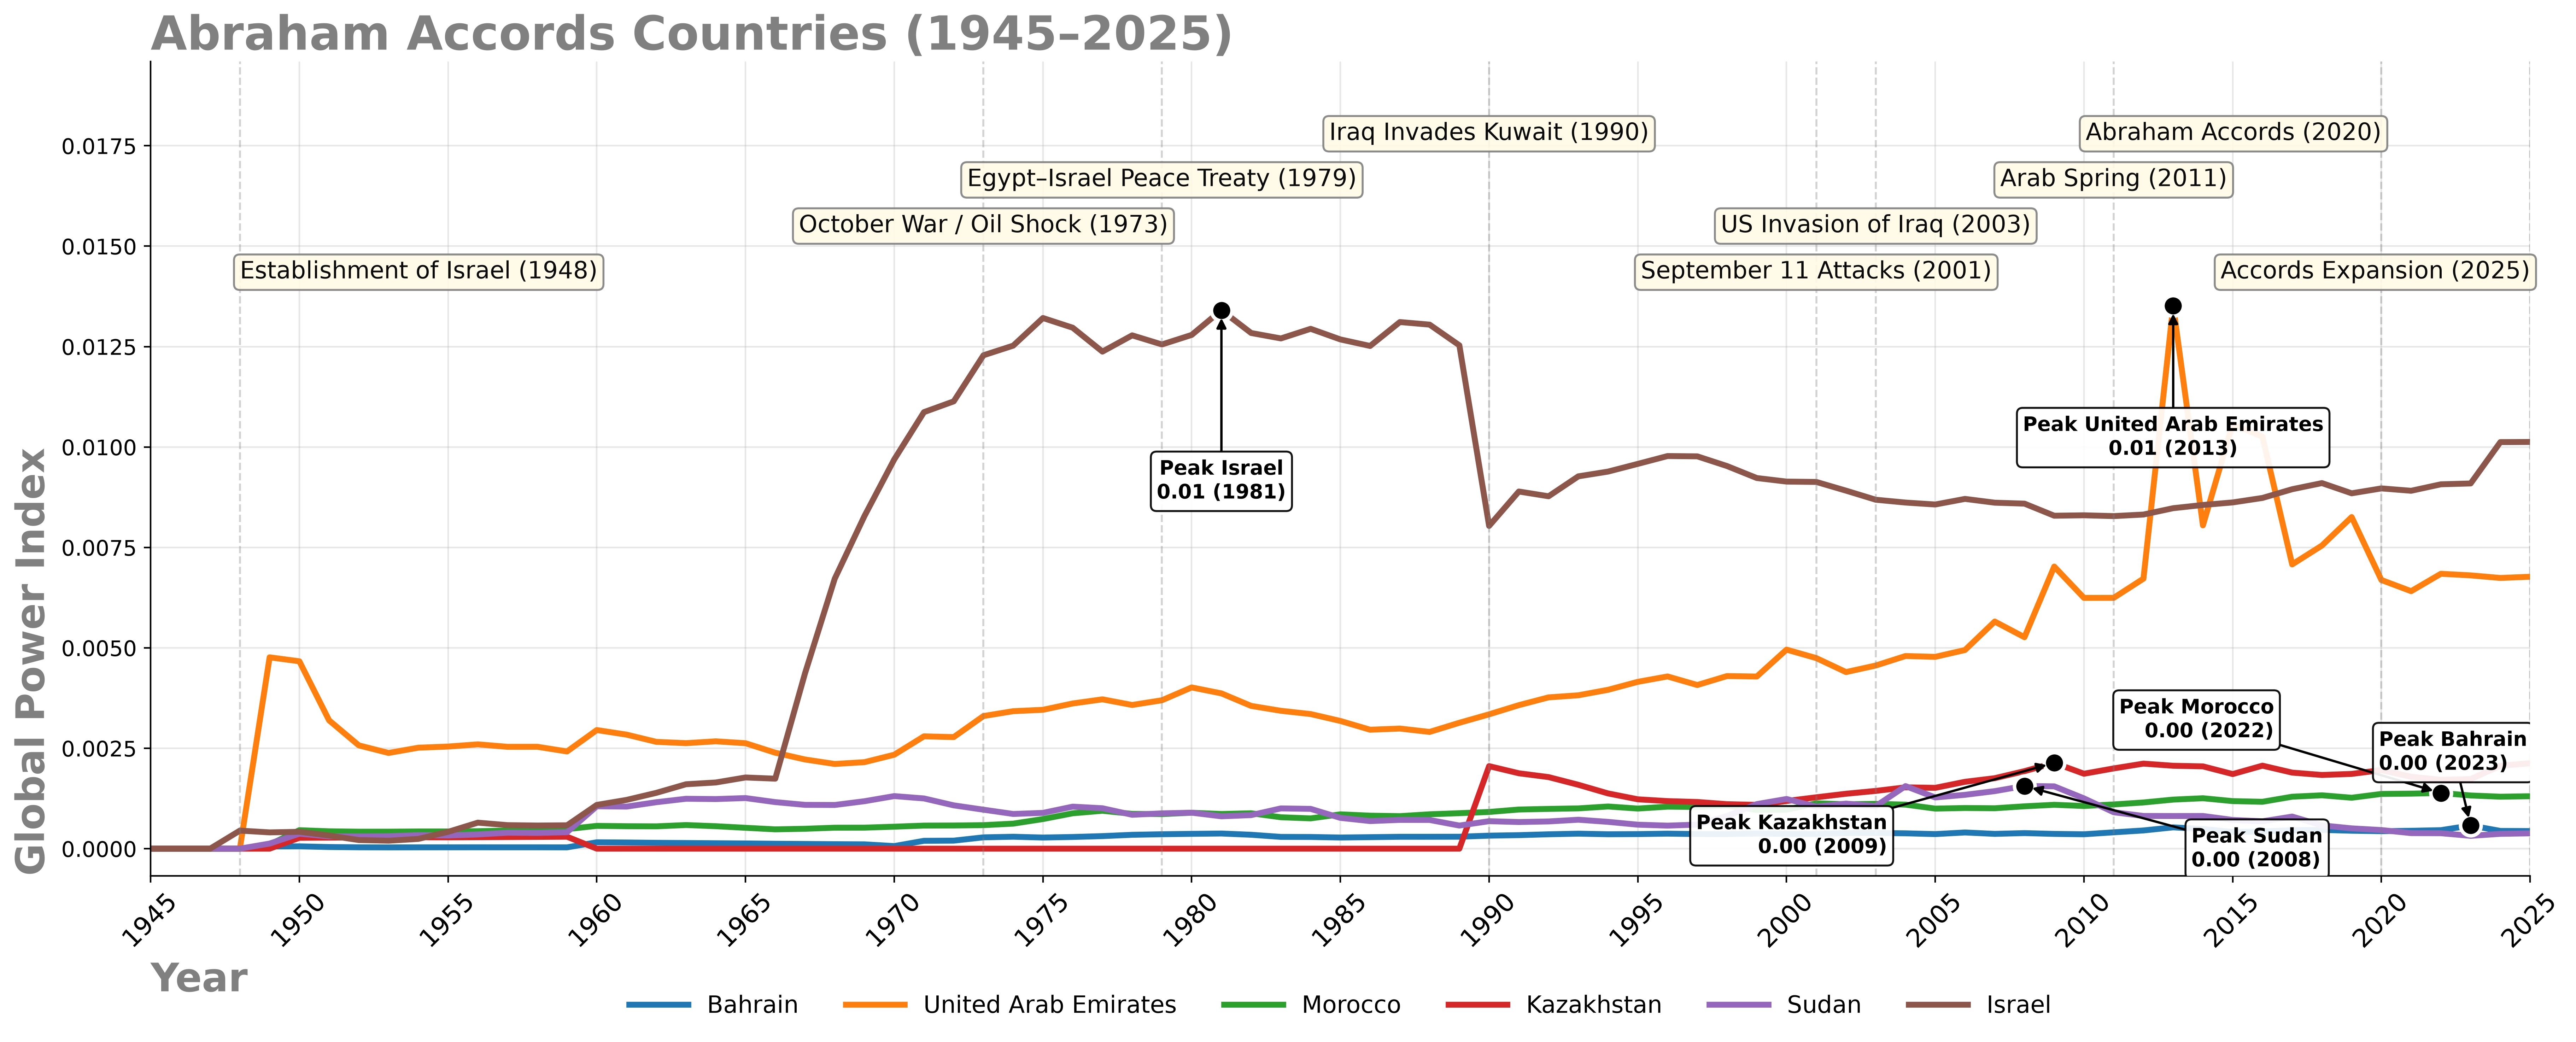

In [ ]:
drop_cols = [c for c in abim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))]
if drop_cols:
    abim = abim.drop(columns=drop_cols)

fig, ax = plt.subplots(figsize=(18, 9), dpi=400)

# ════════════════════════════════════════════════════════════════════
#  بخش ۱ — خطوط اصلی (پهن‌تر: linewidth=3)
# ════════════════════════════════════════════════════════════════════
abim.plot(ax=ax, linewidth=3)
colors = plt.cm.tab10(np.linspace(0, 1, len(abim.columns)))

y_min   = abim.min().min()
y_max   = abim.max().max()
y_range = y_max - y_min

# ─── محدوده‌ها و چیدمان را همین‌جا تنظیم می‌کنیم (لازم برای کلیپ دقیق) ───
ax.set_xticks(np.arange(1945, 2026, 5))
ax.set_xlim(1945, 2025)
ax.tick_params(axis='x', rotation=45, labelsize=13)
ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.40 * y_range)
fig.subplots_adjust(left=0.06, right=0.995, top=0.90, bottom=0.24)

# ════════════════════════════════════════════════════════════════════
#  بخش ۲ — نقاط پیک (سیاه، داخل نمودار، با آفست چرخشی)
# ════════════════════════════════════════════════════════════════════
peak_data = []
for i, country in enumerate(abim.columns):
    s = abim[country].dropna()
    if s.empty:
        continue
    x_peak, y_peak = s.idxmax(), s.max()
    peak_data.append((x_peak, y_peak, country, i))

peak_data.sort(key=lambda p: -p[1])          # بلندترها اول ⇒ مارپیچ پخش می‌شن

peak_offsets = [
    (0,   -55), (0,    55),
    (-85, -25), (85,  -25),
    (-85,  25), (85,   25),
    (-130,  0), (130,   0),
    (0,   -85), (0,    85),
]

for k, (x_peak, y_peak, country, i) in enumerate(peak_data):
    ax.scatter(x_peak, y_peak, color='black', s=110,
               edgecolor='white', linewidth=1.8, zorder=6)

    dx, dy = peak_offsets[k % len(peak_offsets)]
    ha = 'center' if abs(dx) < 10 else ('left' if dx > 0 else 'right')
    va = 'center' if abs(dy) < 10 else ('bottom' if dy > 0 else 'top')
for k, (x_peak, y_peak, country, i) in enumerate(peak_data):
    ax.scatter(x_peak, y_peak, color='black', s=110,
               edgecolor='white', linewidth=1.8, zorder=6)

    dx, dy = peak_offsets[k % len(peak_offsets)]

    # ─── اسرائیل: همیشه برچسب از زیر خط ───
    if str(country).strip().lower() == 'israel':
        dx, dy = 0, -75

    ha = 'center' if abs(dx) < 10 else ('left' if dx > 0 else 'right')
    va = 'center' if abs(dy) < 10 else ('bottom' if dy > 0 else 'top')

    ax.annotate(
        f"Peak {country}\n{y_peak:.2f} ({x_peak})",
        xy=(x_peak, y_peak), xytext=(dx, dy),
        textcoords='offset points',
        fontsize=10, color='black', fontweight='bold',
        va=va, ha=ha,
        arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                        shrinkA=0, shrinkB=4),
        bbox=dict(boxstyle='round,pad=0.3', fc='white',
                  ec='black', alpha=0.92),
        annotation_clip=True, clip_on=True, zorder=7,
    )
    ax.annotate(
        f"Peak {country}\n{y_peak:.4f} ({x_peak})",
        xy=(x_peak, y_peak), xytext=(dx, dy),
        textcoords='offset points',
        fontsize=10, color='black', fontweight='bold',
        va=va, ha=ha,
        arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                        shrinkA=0, shrinkB=4),
        bbox=dict(boxstyle='round,pad=0.3', fc='white',
                  ec='black', alpha=0.92),
        annotation_clip=True, clip_on=True, zorder=7,
    )

# ════════════════════════════════════════════════════════════════════
#  بخش ۲.۵ — اصلاح دقیق کلیپ (اندازه‌گیری عرض واقعی هر برچسب پیک)
# ════════════════════════════════════════════════════════════════════
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
ax_bb    = ax.get_window_extent()
pad      = 8

for ann in ax.texts:
    if not ann.get_text().startswith("Peak"):
        continue

    bb = ann.get_window_extent(renderer)

    dx_shift = dy_shift = 0.0
    if   bb.x1 > ax_bb.x1 - pad:  dx_shift = ax_bb.x1 - pad - bb.x1
    elif bb.x0 < ax_bb.x0 + pad:  dx_shift = ax_bb.x0 + pad - bb.x0
    if   bb.y1 > ax_bb.y1 - pad:  dy_shift = ax_bb.y1 - pad - bb.y1
    elif bb.y0 < ax_bb.y0 + pad:  dy_shift = ax_bb.y0 + pad - bb.y0

    if dx_shift or dy_shift:
        scale = 72.0 / fig.dpi              # pixel → points
        ox, oy = ann.get_position()
        ann.set_position((ox + dx_shift * scale,
                          oy + dy_shift * scale))

fig.canvas.draw()

# ════════════════════════════════════════════════════════════════════
#  بخش ۳ — رویدادها (۴ ردیف + چسبیدن به لبه)
# ════════════════════════════════════════════════════════════════════
events = {
    1948: "Establishment of Israel",
    1973: "October War / Oil Shock",
    1979: "Egypt–Israel Peace Treaty",
    1990: "Iraq Invades Kuwait",
    2001: "September 11 Attacks",
    2003: "US Invasion of Iraq",
    2011: "Arab Spring",
    2020: "Abraham Accords",
    2025: "Accords Expansion",
}

n_rows       = 4
y_event_base = y_max + 0.04 * y_range
step         = 0.085 * y_range

for i_ev, (year, label) in enumerate(events.items()):
    if year not in abim.index:
        continue
    ax.axvline(year, color='gray', linestyle='--', alpha=0.35, linewidth=1)

    row    = i_ev % n_rows
    y_text = y_event_base + row * step

    if year >= 2020:
        ha_val = 'right'
    elif year <= 1950:
        ha_val = 'left'
    else:
        ha_val = 'center'

    ax.annotate(
        f"{label} ({year})",
        xy=(year, y_max), xytext=(year, y_text),
        fontsize=12, color='#0a0a0a',
        ha=ha_val, va='bottom',
        bbox=dict(boxstyle='round,pad=0.25', fc='#fffbe6',
                  ec='gray', alpha=0.9),
        annotation_clip=True, zorder=4,
    )

# ════════════════════════════════════════════════════════════════════

# ════════════════════════════════════════════════════════════════════


# ════════════════════════════════════════════════════════════════════
#  بخش ۵ — عنوان و برچسب محورها
# ════════════════════════════════════════════════════════════════════
ax.set_title("Abraham Accords Countries (1945–2025)",
             fontsize=24, fontweight='bold', loc="left",color='gray')
ax.set_xlabel("Year", fontweight='bold', fontsize=20, loc='left',color='gray')
ax.set_ylabel("Global Power Index", fontsize=20, fontweight='bold', loc='bottom',color='gray')
ax.grid(True, alpha=0.3)

# ════════════════════════════════════════════════════════════════════
#  بخش ۶ — لجند افقی زیر نمودار
# ════════════════════════════════════════════════════════════════════
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(abim.columns), 7),
    fontsize=12,
    frameon=False,
    handlelength=2.5,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ════════════════════════════════════════════════════════════════════
#  بخش ۷ — ذخیره
# ════════════════════════════════════════════════════════════════════
plt.savefig("abraham_accords.png", dpi=300, bbox_inches='tight')
plt.savefig("abraham_accords.pdf", bbox_inches='tight')
plt.show()

In [47]:
country_events = {
    "Israel": {
        1948: "Independence",
        1967: "Six-Day War",
        1973: "Yom Kippur War",
        1979: "Egypt Peace Treaty",
        1993: "Oslo Accords",
        1994: "Jordan Peace Treaty",
        2000: "Second Intifada",
        2020: "Abraham Accords",
    },
    "UAE": {
        1971: "Independence",
        2020: "Abraham Accords",
    },
    "Bahrain": {
        1971: "Independence",
        2020: "Abraham Accords",
    },
    "Morocco": {
        1956: "Independence",
        1975: "Green March",
        2020: "Abraham Accords",
    },
    "Sudan": {
        1956: "Independence",
        2020: "Abraham Accords",
    },
    "Egypt": {
        1952: "Revolution",
        1973: "Yom Kippur War",
        1979: "Peace Treaty with Israel",
    },
    "Jordan": {
        1946: "Independence",
        1967: "Six-Day War",
        1994: "Peace Treaty with Israel",
    },
    "Kazakhstan": {
        1991: "Independence",
    },
}

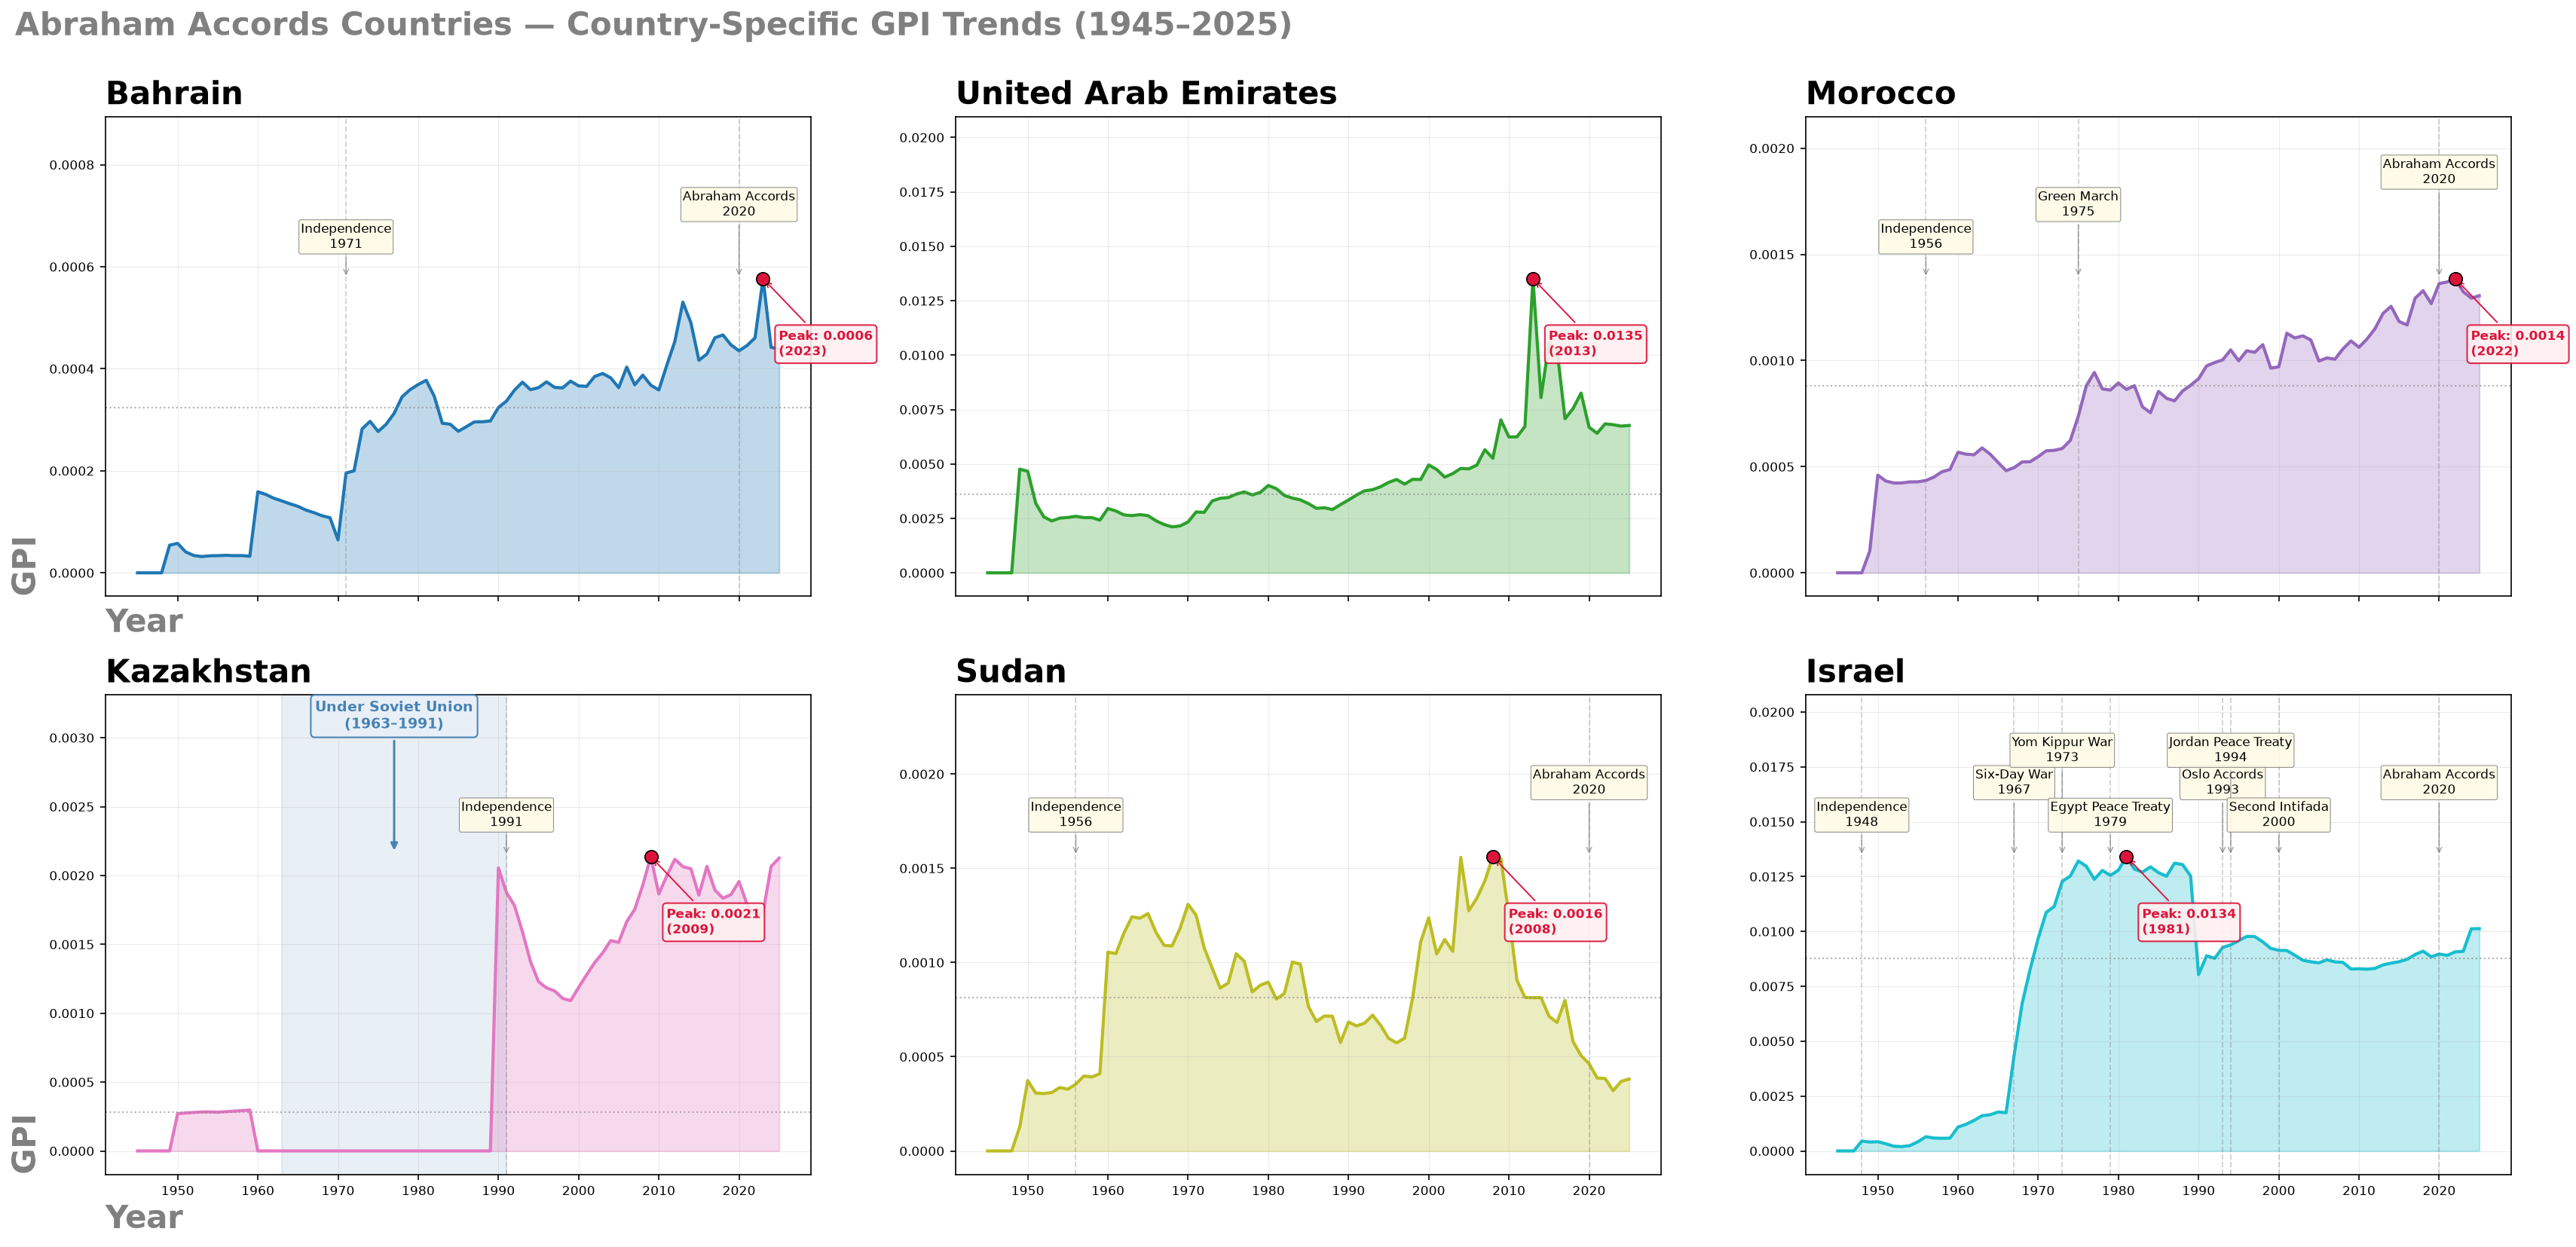

In [48]:
drop_cols = [c for c in abim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))]
if drop_cols:
    abim = abim.drop(columns=drop_cols)

n_countries = len(abim.columns)
n_cols = 3
n_rows = int(np.ceil(n_countries / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                          figsize=(23, 4 * n_rows + 3),
                          sharex=True)
axes = np.array(axes).flatten()
colors = plt.cm.tab10(np.linspace(0, 1, n_countries))

# ════════════════════════════════════════════════════════════════════
#  حلقه اصلی (فقط یک بار — حلقه‌ی dead حذف شد)
# ════════════════════════════════════════════════════════════════════
for i, country in enumerate(abim.columns):
    ax = axes[i]
    s = abim[country].dropna()
    if s.empty:
        ax.set_visible(False)
        continue

    y_min, y_max = s.min(), s.max()
    y_range = y_max - y_min if y_max > y_min else 1

    # ---- خط + ناحیه ----
    ax.plot(s.index, s.values, color=colors[i], linewidth=2)
    ax.fill_between(s.index, s.values, alpha=0.28, color=colors[i])

    # ---- میانه ----
    med = s.median()
    ax.axhline(med, color='gray', linestyle=':', alpha=0.6, linewidth=1)

    # ---- پیک ----
    x_pk, y_pk = s.idxmax(), s.max()
    ax.scatter(x_pk, y_pk, color='crimson', s=70,
               zorder=6, edgecolor='black', linewidth=0.8)

    if y_pk > y_min + 0.7 * y_range:
        xy_txt, va = (10, -32), 'top'
    else:
        xy_txt, va = (10, 12), 'bottom'

    ax.annotate(
        f"Peak: {y_pk:.4f}\n({x_pk})",
        xy=(x_pk, y_pk), xytext=xy_txt,
        textcoords='offset points',
        fontsize=8, color='crimson', fontweight='bold',
        va=va, ha='left',
        arrowprops=dict(arrowstyle='->', color='crimson', lw=0.9),
        bbox=dict(boxstyle='round,pad=0.3', fc='#fff0f0',
                  ec='crimson', alpha=0.9),
        annotation_clip=True,
    )

    # ════════════════════════════════════════════════════════════════
    #  ⭐ (NEW) دوره‌ی شوروی برای قزاقستان ۱۹۶۳–۱۹۹۱
    # ════════════════════════════════════════════════════════════════
    if country == "Kazakhstan":
        ax.axvspan(1963, 1991, alpha=0.12, color='steelblue', zorder=0)
        ax.annotate(
            "Under Soviet Union\n(1963–1991)",
            xy=(1977, y_max),                       # نوک فلش: بالای داده‌ها
            xytext=(1977, y_max + 0.42 * y_range),  # متن بالای همه چیز
            textcoords='data',
            fontsize=9, color='steelblue', fontweight='bold',
            ha='center', va='bottom',
            arrowprops=dict(arrowstyle='-|>', color='steelblue',
                            lw=1.4, shrinkB=4),
            bbox=dict(boxstyle='round,pad=0.3', fc='#e8f0f8',
                      ec='steelblue', alpha=0.95, linewidth=1),
            annotation_clip=True, zorder=10,
        )

    # ════════════════════════════════════════════════════════════════
    #  ⭐ (NEW) رخدادها با فلش (قبلاً ax.text بود ⇒ الان ax.annotate)
    # ════════════════════════════════════════════════════════════════
    ev = country_events.get(country, {})
    for j, (yr, lbl) in enumerate(ev.items()):
        if yr not in s.index:
            continue

        ax.axvline(yr, color='gray', linestyle='--',
                   alpha=0.35, linewidth=0.9)

        y_txt = y_max + 0.09 * y_range + (j % 3) * 0.11 * y_range

        ax.annotate(
            f"{lbl}\n{yr}",
            xy=(yr, y_max),            # ← نوک فلش: بالای خط عمودی
            xytext=(yr, y_txt),        # ← متن
            textcoords='data',
            fontsize=8, color='black',
            ha='center', va='bottom',
            arrowprops=dict(arrowstyle='->', color='gray',
                            lw=0.7, alpha=0.7, shrinkB=2),
            bbox=dict(boxstyle='round,pad=0.15', fc='#fffbe6', ec='gray',
                      alpha=0.9, linewidth=0.5),
            clip_on=True,
            annotation_clip=True,
        )

     # ---- ظاهر ----
    ax.set_title(country, fontsize=20, fontweight='bold',
                 loc='left', color='black', pad=8)
    ax.grid(alpha=0.25, linewidth=0.5)

    # ⭐ فقط بحرین و قزاقستان: برچسب محور X و Y
    if country in ("Bahrain", "Kazakhstan"):
        ax.set_ylabel("GPI", fontweight='bold', fontsize=20, loc='bottom',color='gray')
        ax.set_xlabel("Year", fontweight='bold', fontsize=20, loc='left',color='gray')

    ax.tick_params(labelsize=8)
    ax.set_ylim(y_min - 0.08 * y_range, y_max + 0.55 * y_range)


fig.suptitle(
    "Abraham Accords Countries — Country-Specific GPI Trends (1945–2025)"
    ,
    fontsize=20, fontweight='bold',color='gray',
    y=1, ha='right'
)

plt.tight_layout()
plt.savefig("abraham_country_events.png", dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()

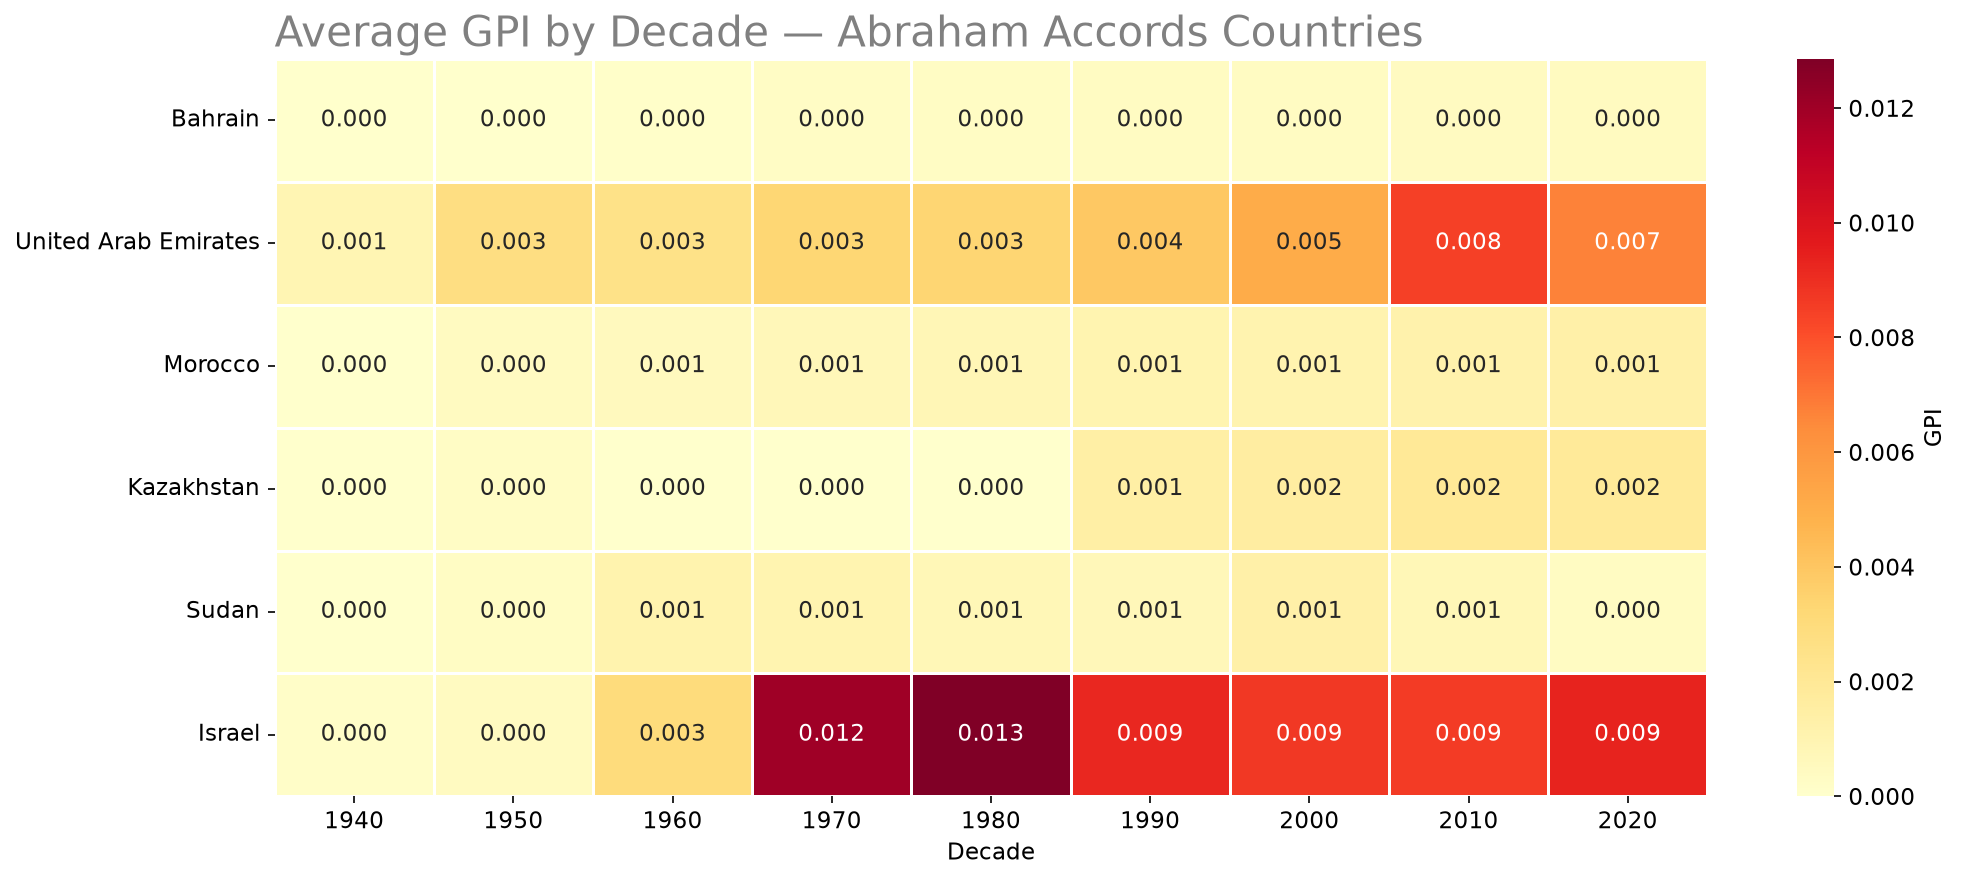

In [49]:
abim_clean = abim.drop(
    columns=[c for c in abim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))],
    errors='ignore'
)

# ════════════════════════════════════════════════════════════════════
#  میانگین هر دهه
# ════════════════════════════════════════════════════════════════════
decade_avg = abim_clean.copy()
decade_avg['Decade'] = (decade_avg.index // 10) * 10
decade_avg = decade_avg.groupby('Decade').mean()

# ════════════════════════════════════════════════════════════════════
#  هیت‌مپ
# ════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    decade_avg.T,
    cmap='YlOrRd',
    annot=True, fmt='.3f',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'GPI'},
)
ax.set_title("Average GPI by Decade — Abraham Accords Countries",
             fontsize=20, loc='left', color='gray')
ax.set_xlabel("Decade")
plt.tight_layout()
plt.show()

In [50]:
mbim["sum all of makeh"] = df.loc[1945:2025, useful_columns].sum(axis=1)
abim["sum all of Abraham"] = df.loc[1945:2025, useful_columns1].sum(axis=1)

In [75]:
abim.dropna().any()
abim

,Bahrain,United Arab Emirates,Morocco,Kazakhstan,Sudan,Israel
Year,,,,,,
1945,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1946,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1947,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1948,0.000000,0.000000,0.000000,0.000000,0.000000,0.000450
1949,0.000054,0.004764,0.000103,0.000000,0.000127,0.000405
...,...,...,...,...,...,...
2021,0.000445,0.006410,0.001370,0.001790,0.000387,0.008910
2022,0.000461,0.006844,0.001386,0.001714,0.000384,0.009071
2023,0.000577,0.006804,0.001324,0.001731,0.000320,0.009092


Univariate


In [101]:
mbim["sum all of makeh"] = df.loc[1945:2025, useful_columns].sum(axis=1)
mbim

,Turkey,Pakistan,Saudi Arabia,sum all of makeh
Year,,,,
1945,0.002624,0.000000,0.000724,0.003348
1946,0.002949,0.000000,0.001670,0.004619
1947,0.002855,0.003657,0.002238,0.008750
1948,0.003019,0.004624,0.001216,0.008859
1949,0.002132,0.003930,0.001689,0.007751
...,...,...,...,...
2021,0.011369,0.008221,0.015992,0.035582
2022,0.010990,0.008032,0.016266,0.035287
2023,0.010984,0.007838,0.014171,0.032994


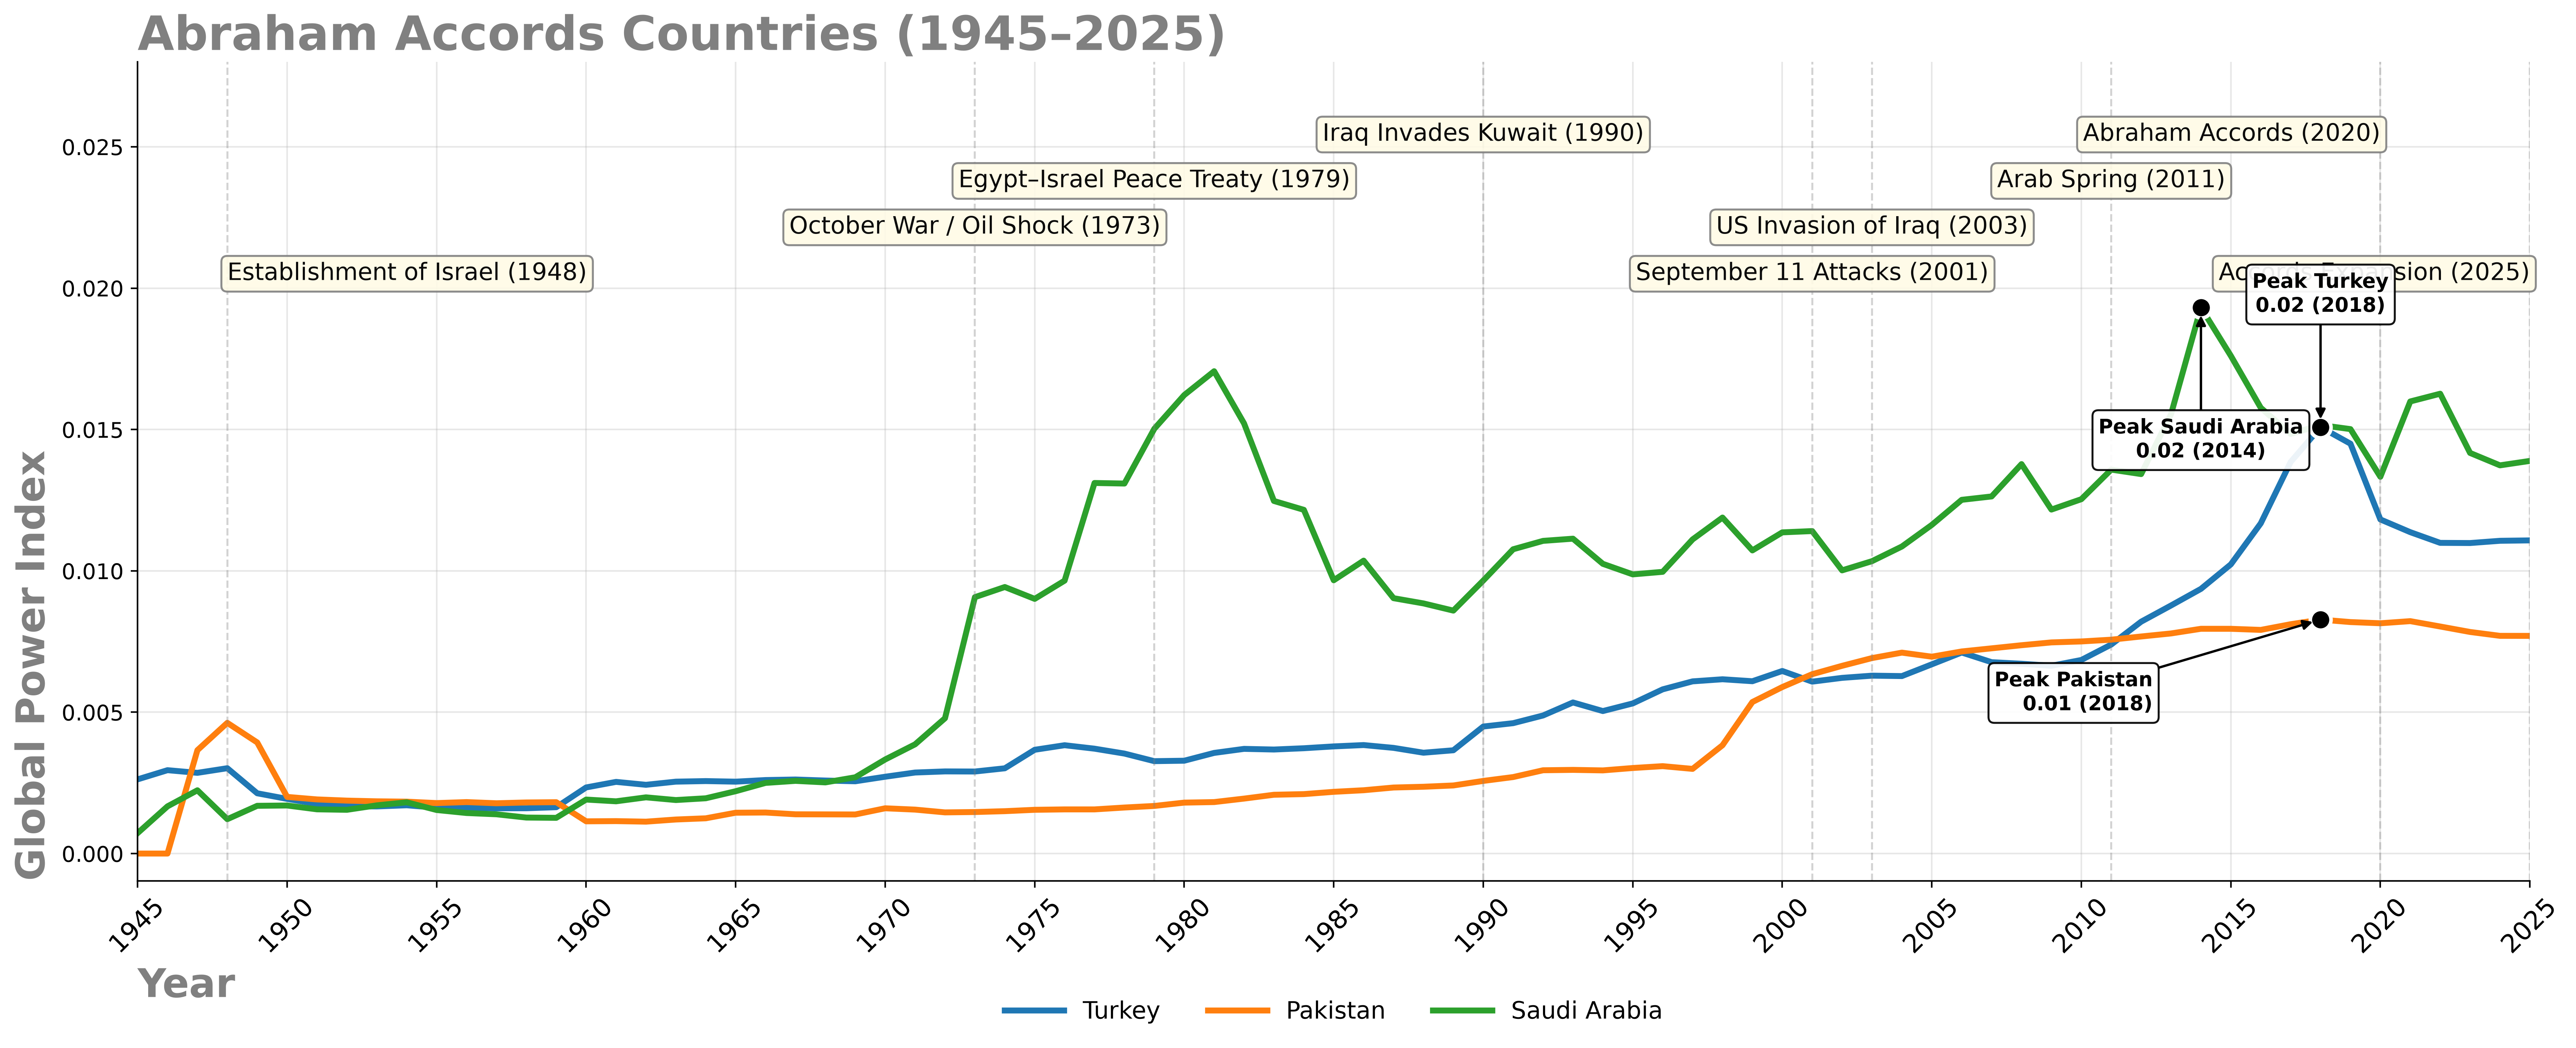

In [102]:
drop_cols = [c for c in mbim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))]
if drop_cols:
    mbim = mbim.drop(columns=drop_cols)
mbim = mbim.select_dtypes(include="number")

# ════════════════════════════════════════════════════════════════════
#  ۱) Figure + خطوط اصلی
# ════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(18, 9), dpi=400)
mbim.plot(ax=ax, linewidth=3)

y_min   = mbim.min().min()
y_max   = mbim.max().max()
y_range = y_max - y_min
if y_range == 0:
    y_range = 1

ax.set_xticks(np.arange(1945, 2026, 5))
ax.set_xlim(1945, 2025)
ax.tick_params(axis='x', rotation=45, labelsize=13)
ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.45 * y_range)
fig.subplots_adjust(left=0.06, right=0.995, top=0.90, bottom=0.26)

# ════════════════════════════════════════════════════════════════════
#  ۲) نقاط پیک  (یک annotate برای هر پیک)
# ════════════════════════════════════════════════════════════════════
peak_data = []
for i, country in enumerate(mbim.columns):
    s = mbim[country].dropna()
    if s.empty:
        continue
    peak_data.append((s.idxmax(), s.max(), country, i))

peak_data.sort(key=lambda p: -p[1])

peak_offsets = [
    (0,   -55), (0,    55),
    (-85, -25), (85,  -25),
    (-85,  25), (85,   25),
    (-130,  0), (130,   0),
    (0,   -85), (0,    85),
]

for k, (x_peak, y_peak, country, i) in enumerate(peak_data):
    ax.scatter(x_peak, y_peak, color='black', s=110,
               edgecolor='white', linewidth=1.8, zorder=6)

    dx, dy = peak_offsets[k % len(peak_offsets)]

    if str(country).strip().lower() == 'israel':
        dx, dy = 0, -75

    ha = 'center' if abs(dx) < 10 else ('left' if dx > 0 else 'right')
    va = 'center' if abs(dy) < 10 else ('bottom' if dy > 0 else 'top')

    ax.annotate(
        f"Peak {country}\n{y_peak:.2f} ({x_peak})",
        xy=(x_peak, y_peak), xytext=(dx, dy),
        textcoords='offset points',
        fontsize=10, color='black', fontweight='bold',
        va=va, ha=ha,
        arrowprops=dict(arrowstyle='-|>', color='black', lw=1.2,
                        shrinkA=0, shrinkB=4),
        bbox=dict(boxstyle='round,pad=0.3', fc='white',
                  ec='black', alpha=0.92),
        annotation_clip=True, clip_on=True, zorder=7,
    )

# ════════════════════════════════════════════════════════════════════
#  ۳) اصلاح دقیق کلیپ برچسب‌های پیک
# ════════════════════════════════════════════════════════════════════
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
ax_bb    = ax.get_window_extent()
pad      = 8

for ann in ax.texts:
    if not ann.get_text().startswith("Peak"):
        continue

    bb = ann.get_window_extent(renderer)

    dx_shift = dy_shift = 0.0
    if   bb.x1 > ax_bb.x1 - pad:  dx_shift = ax_bb.x1 - pad - bb.x1
    elif bb.x0 < ax_bb.x0 + pad:  dx_shift = ax_bb.x0 + pad - bb.x0
    if   bb.y1 > ax_bb.y1 - pad:  dy_shift = ax_bb.y1 - pad - bb.y1
    elif bb.y0 < ax_bb.y0 + pad:  dy_shift = ax_bb.y0 + pad - bb.y0

    if dx_shift or dy_shift:
        scale = 72.0 / fig.dpi
        ox, oy = ann.get_position()
        ann.set_position((ox + dx_shift * scale,
                          oy + dy_shift * scale))

fig.canvas.draw()

# ════════════════════════════════════════════════════════════════════
#  ۴) رویدادها (۴ ردیف + چسبیدن به لبه)
# ════════════════════════════════════════════════════════════════════
events = {
    1948: "Establishment of Israel",
    1973: "October War / Oil Shock",
    1979: "Egypt–Israel Peace Treaty",
    1990: "Iraq Invades Kuwait",
    2001: "September 11 Attacks",
    2003: "US Invasion of Iraq",
    2011: "Arab Spring",
    2020: "Abraham Accords",
    2025: "Accords Expansion",
}

n_rows       = 4
y_event_base = y_max + 0.04 * y_range
step         = 0.085 * y_range

for i_ev, (year, label) in enumerate(events.items()):
    if year not in mbim.index:
        continue
    ax.axvline(year, color='gray', linestyle='--', alpha=0.35, linewidth=1)

    row    = i_ev % n_rows
    y_text = y_event_base + row * step

    if   year >= 2020:  ha_val = 'right'
    elif year <= 1950:  ha_val = 'left'
    else:               ha_val = 'center'

    ax.annotate(
        f"{label} ({year})",
        xy=(year, y_max), xytext=(year, y_text),
        fontsize=12, color='#0a0a0a',
        ha=ha_val, va='bottom',
        bbox=dict(boxstyle='round,pad=0.25', fc='#fffbe6',
                  ec='gray', alpha=0.9),
        annotation_clip=True, zorder=4,
    )

# ════════════════════════════════════════════════════════════════════
#  ۵) عنوان و برچسب محورها
# ════════════════════════════════════════════════════════════════════
ax.set_title("Abraham Accords Countries (1945–2025)",
             fontsize=24, fontweight='bold', loc="left", color='gray')
ax.set_xlabel("Year", fontweight='bold', fontsize=20,
              loc='left', color='gray')
ax.set_ylabel("Global Power Index", fontweight='bold', fontsize=20,
              loc='bottom', color='gray')
ax.grid(True, alpha=0.3)

# ════════════════════════════════════════════════════════════════════
#  ۶) لجند افقی زیر نمودار
# ════════════════════════════════════════════════════════════════════
ax.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=min(len(mbim.columns), 7),
    fontsize=12,
    frameon=False,
    handlelength=2.5,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# ════════════════════════════════════════════════════════════════════
#  ۷) ذخیره
# ════════════════════════════════════════════════════════════════════
plt.savefig("abraham_accords.png", dpi=300, bbox_inches='tight',
            facecolor='white')
plt.savefig("abraham_accords.pdf", bbox_inches='tight', facecolor='white')
plt.show()

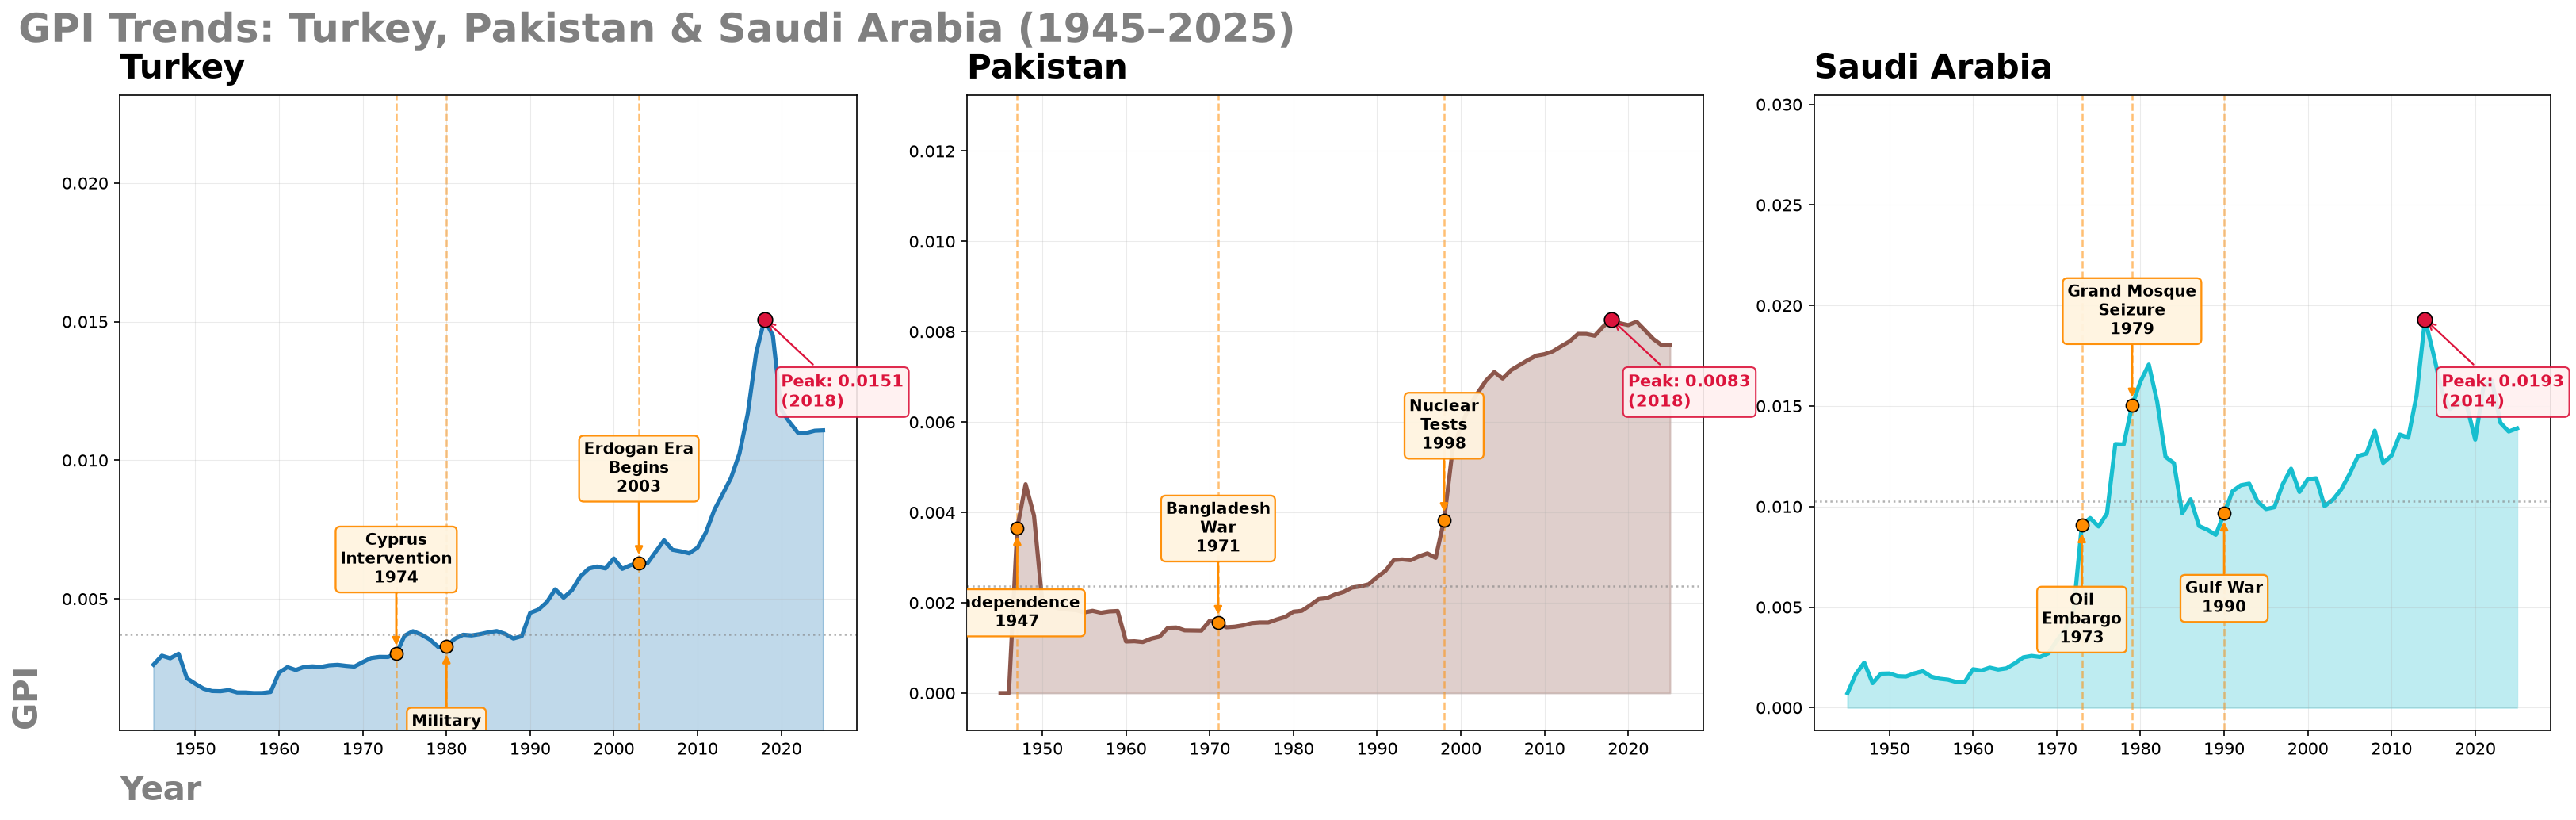

In [103]:
drop_cols = [c for c in mbim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))]
if drop_cols:
    mbim = mbim.drop(columns=drop_cols)

mbim = mbim.select_dtypes(include="number")

# ════════════════════════════════════════════════════════════════════
#  ۱) انتخاب دقیقا ۳ کشور (ترکیه، پاکستان، عربستان)
# ════════════════════════════════════════════════════════════════════
# ما اسم‌ها را مستقیماً صدا می‌زنیم تا مطمئن شویم همین‌ها رسم می‌شوند
target_countries = ['Turkey', 'Pakistan', 'Saudi Arabia']
cols_to_plot = [c for c in target_countries if c in mbim.columns]

# ════════════════════════════════════════════════════════════════════
#  ۲) رویدادهای مهم (اضافه شدن پاکستان و عربستان)
# ════════════════════════════════════════════════════════════════════
key_events = {
    "Turkey": [
        (1974, "Cyprus\nIntervention", "up"),
        (1980, "Military\nCoup",       "down"),
        (2003, "Erdogan Era\nBegins",  "up"),
    ],
    "Pakistan": [
        (1947, "Independence",         "down"),
        (1971, "Bangladesh\nWar",      "up"),
        (1998, "Nuclear\nTests",       "up"),
    ],
    "Saudi Arabia": [
        (1973, "Oil\nEmbargo",         "down"),
        (1979, "Grand Mosque\nSeizure","up"),
        (1990, "Gulf War",             "down"),
    ]
}

# ────────────────────────────────────────────────────────────────────
#  ۳) چیدمان (۱ ردیف، ۳ ستون - کنار هم)
# ────────────────────────────────────────────────────────────────────
n_rows = 1
n_cols = len(cols_to_plot)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 7), sharex=True)
axes = np.array(axes).flatten()
colors = plt.cm.tab10(np.linspace(0, 1, n_cols))

# ────────────────────────────────────────────────────────────────────
#  ۴) حلقه اصلی رسم
# ────────────────────────────────────────────────────────────────────
for i, country in enumerate(cols_to_plot):
    ax = axes[i]
    s  = mbim[country].dropna()
    if s.empty:
        ax.set_visible(False)
        continue

    y_min, y_max = s.min(), s.max()
    y_range = y_max - y_min if y_max > y_min else 1

    # خط و ناحیه
    ax.plot(s.index, s.values, color=colors[i], linewidth=2.5)
    ax.fill_between(s.index, s.values, alpha=0.28, color=colors[i])

    # میانه
    med = s.median()
    ax.axhline(med, color='gray', linestyle=':', alpha=0.6, linewidth=1.2)

    # پیک (قرمز)
    x_pk, y_pk = s.idxmax(), s.max()
    ax.scatter(x_pk, y_pk, color='crimson', s=80,
               zorder=6, edgecolor='black', linewidth=0.8)

    if y_pk > y_min + 0.7 * y_range:
        xy_txt, va = (10, -32), 'top'
    else:
        xy_txt, va = (10, 12), 'bottom'

    ax.annotate(
        f"Peak: {y_pk:.4f}\n({x_pk})",
        xy=(x_pk, y_pk), xytext=xy_txt,
        textcoords='offset points',
        fontsize=10, color='crimson', fontweight='bold',
        va=va, ha='left',
        arrowprops=dict(arrowstyle='->', color='crimson', lw=1.1),
        bbox=dict(boxstyle='round,pad=0.3', fc='#fff0f0',
                  ec='crimson', alpha=0.9),
        annotation_clip=True,
    )

    # ════════════════════════════════════════════════════════════════
    #  رویدادهای مهم (نارنجی)
    # ════════════════════════════════════════════════════════════════
    if country in key_events:
        for yr, lbl, side in key_events[country]:
            if yr not in s.index:
                continue

            y_at = s.loc[yr]
            ax.axvline(yr, color='darkorange', linestyle='--',
                       alpha=0.55, linewidth=1.2, zorder=1)
            ax.scatter(yr, y_at, color='darkorange', s=60,
                       zorder=8, edgecolor='black', linewidth=0.8)

            if   side == "up":    dx, dy, ha, va =  0,  40, 'center', 'bottom'
            elif side == "down":  dx, dy, ha, va =  0, -40, 'center', 'top'
            elif side == "right": dx, dy, ha, va = 55,   0, 'left',   'center'
            else:                 dx, dy, ha, va = -55,  0, 'right',  'center'

            ax.annotate(
                f"{lbl}\n{yr}",
                xy=(yr, y_at), xytext=(dx, dy),
                textcoords='offset points',
                fontsize=9.5, color='black', fontweight='bold',
                ha=ha, va=va,
                arrowprops=dict(arrowstyle='-|>', color='darkorange',
                                lw=1.3, shrinkA=0, shrinkB=5),
                bbox=dict(boxstyle='round,pad=0.3',
                          fc='#fff4e0', ec='darkorange',
                          alpha=0.95, linewidth=1.1),
                annotation_clip=True, clip_on=True, zorder=9,
            )

    # ── ظاهر هر پنل ─────────────────────────────────────────────────
    ax.set_title(country, fontsize=20, fontweight='bold',
                 loc='left', color='black', pad=10)
    ax.grid(alpha=0.25, linewidth=0.5)
    ax.tick_params(labelsize=10)
    
    # فضای بالا و پایین برای جا شدن آنوتوشن‌ها
    ax.set_ylim(y_min - 0.1 * y_range, y_max + 0.6 * y_range)

    # ════════════════════════════════════════════════════════════════
    #  ⭐ تنظیم برچسب‌های محور X و Y (فقط برای نمودار اول / ترکیه)
    # ════════════════════════════════════════════════════════════════
    if i == 0: 
        ax.set_ylabel("GPI", fontweight='bold', fontsize=20, color='gray', labelpad=10,loc='bottom')
        ax.set_xlabel("Year", fontweight='bold', fontsize=20, color='gray', labelpad=10,loc='left')
    else:
        # پاک کردن برچسب‌ها برای نمودارهای دوم و سوم (پاکستان و عربستان)
        ax.set_ylabel("")
        ax.set_xlabel("")

# ────────────────────────────────────────────────────────────────────
#  ۵) عنوان اصلی در گوشه بالا سمت چپ
# ────────────────────────────────────────────────────────────────────
fig.suptitle(
    "GPI Trends: Turkey, Pakistan & Saudi Arabia (1945–2025)",
    fontsize=24, fontweight='bold', color='gray',
    x=0.01, ha='left', y=0.98
)

# تنظیم فاصله‌ها برای جلوگیری از تداخل
plt.tight_layout()
plt.subplots_adjust(top=0.88, wspace=0.15)
plt.savefig("three_side_by_side.png", dpi=300,
            bbox_inches='tight', facecolor='white')
plt.show()

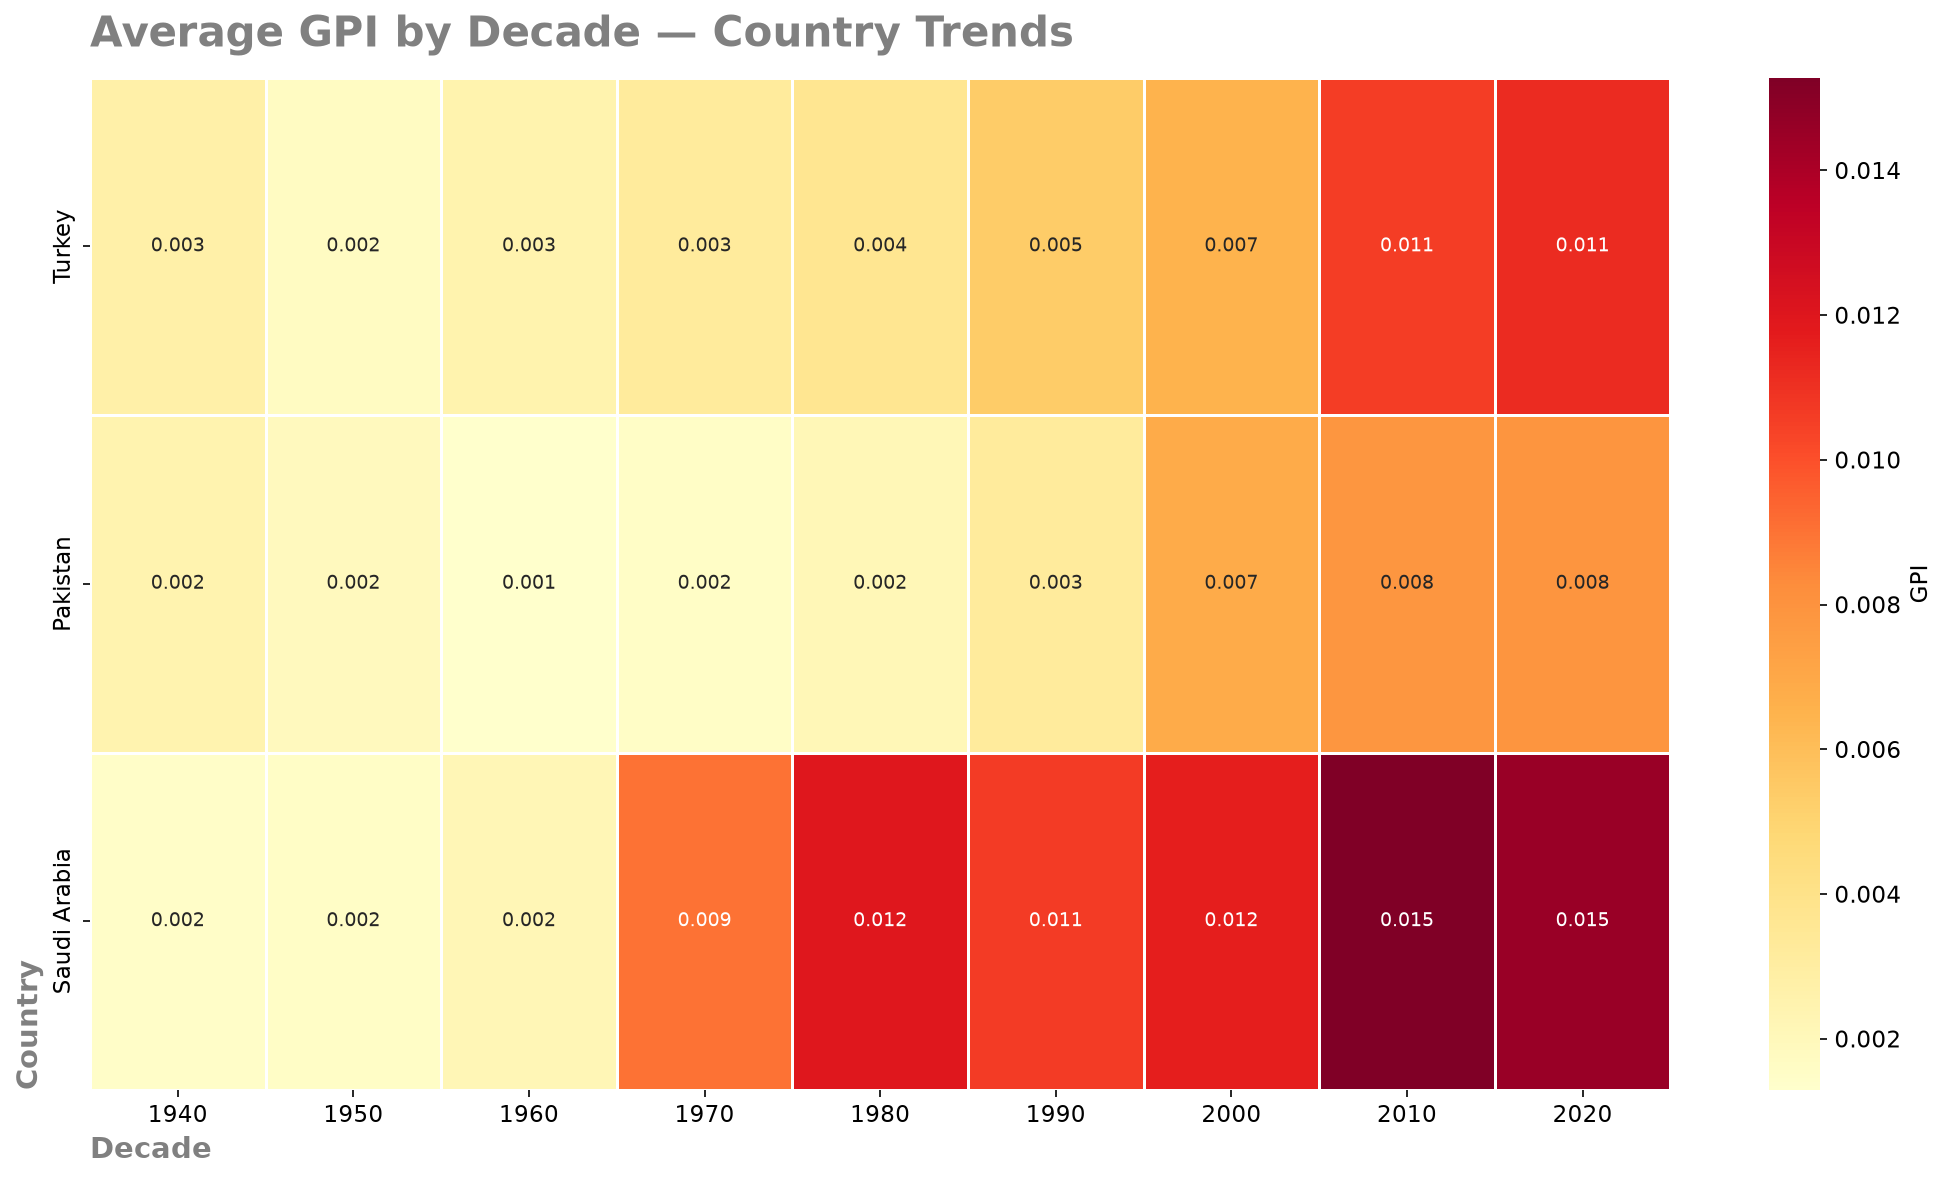

In [104]:
mbim_clean = mbim.drop(
    columns=[c for c in mbim.columns
             if any(k in str(c).lower() for k in ('sum', 'total'))],
    errors='ignore'
)

# اطمینان از اینکه فقط داده‌های عددی باقی می‌مانند
mbim_clean = mbim_clean.select_dtypes(include="number")

# اطمینان از اینکه ایندکس (سال‌ها) از نوع عدد صحیح است تا تقسیم بر ۱۰ درست کار کند
# (اگر ایندکس شما از قبل int است، این خط هیچ تغییری ایجاد نمی‌کند)
mbim_clean.index = mbim_clean.index.astype(int)

# ════════════════════════════════════════════════════════════════════
#  ۲) محاسبه میانگین هر دهه
# ════════════════════════════════════════════════════════════════════
decade_avg = mbim_clean.copy()
decade_avg['Decade'] = (decade_avg.index // 10) * 10
decade_avg = decade_avg.groupby('Decade').mean()

# ════════════════════════════════════════════════════════════════════
#  ۳) رسم هیت‌مپ
# ════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 8))

sns.heatmap(
    decade_avg.T,
    cmap='YlOrRd',
    annot=True, 
    fmt='.3f',
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'GPI'},
    annot_kws={"size": 9}  # سایز فونت اعداد داخل خانه‌ها
)

# تنظیمات ظاهری
ax.set_title("Average GPI by Decade — Country Trends",
             fontsize=20, fontweight='bold', loc='left', color='gray', pad=15)
ax.set_xlabel("Decade", fontsize=14, fontweight='bold', color='gray',loc='left')
ax.set_ylabel("Country", fontsize=14, fontweight='bold', color='gray',loc='bottom')

plt.tight_layout()
plt.savefig("decade_heatmap.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

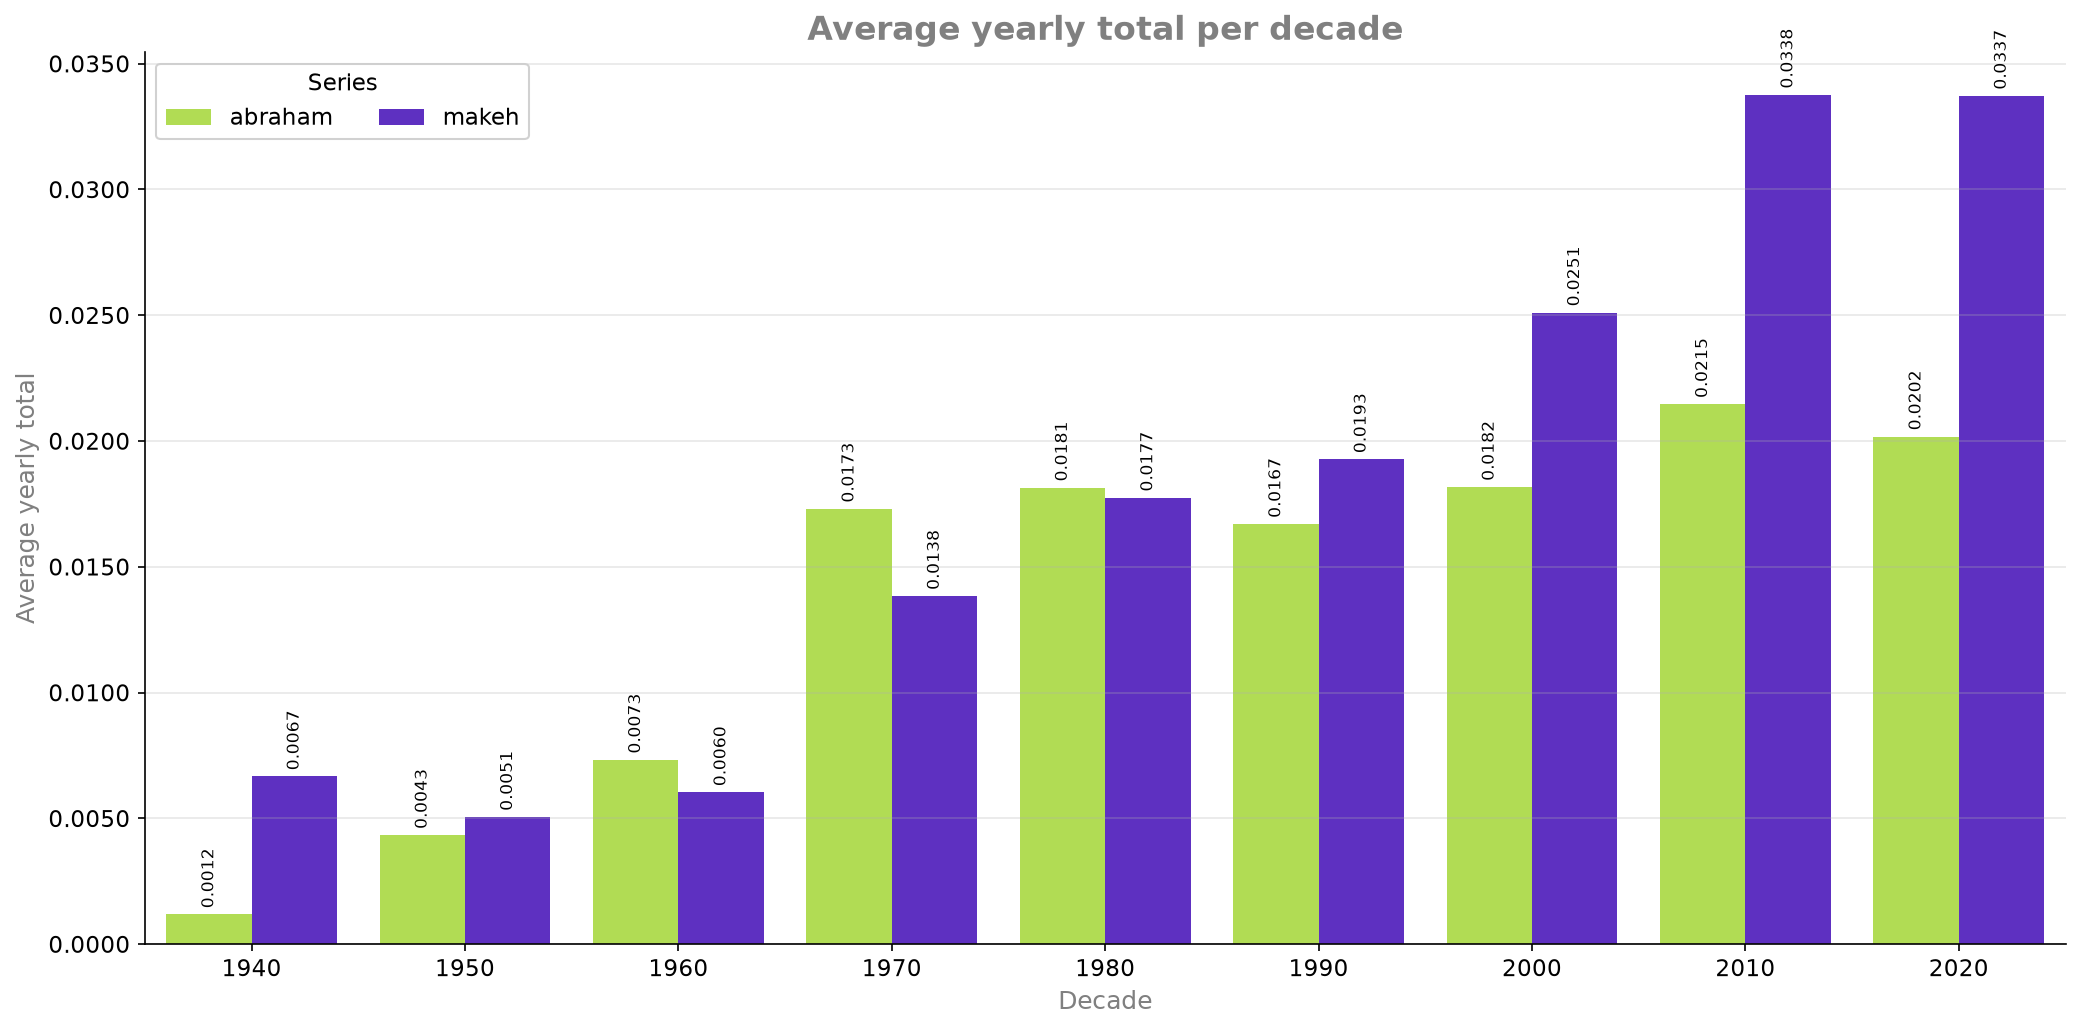

In [111]:
# ════════════════════════════════════════════════════════════════════
#  ۱) آماده‌سازی دیتا (ساخت plot_df از پایه)
# ════════════════════════════════════════════════════════════════════
# محاسبه مجموع سالانه برای هر گروه
abraham_sum = abim.sum(axis=1)
makeh_sum   = mbim.sum(axis=1)

# گروه‌بندی بر اساس دهه و محاسبه میانگین
abraham_decade = abraham_sum.groupby(abraham_sum.index // 10 * 10).mean()
makeh_decade   = makeh_sum.groupby(makeh_sum.index // 10 * 10).mean()

# تبدیل به دیتافریم و ریست کردن ایندکس (تا دهه‌ها تبدیل به ستون بشن)
df_abraham = abraham_decade.reset_index()
df_abraham.columns = ['decade', 'avg']
df_abraham['series'] = 'abraham'

df_makeh = makeh_decade.reset_index()
df_makeh.columns = ['decade', 'avg']
df_makeh['series'] = 'makeh'

# ادغام هر دو دیتافریم در قالب Long
plot_df = pd.concat([df_abraham, df_makeh], ignore_index=True)

# ════════════════════════════════════════════════════════════════════
#  ۲) رسم نمودار (همون کد خودت با اصلاحات)
# ════════════════════════════════════════════════════════════════════
# اطمینان از نوع داده‌ها
plot_df["decade"] = plot_df["decade"].astype("category")
plot_df["avg"]    = pd.to_numeric(plot_df["avg"], errors="coerce")

fig, ax = plt.subplots(figsize=(14, 7))

sns.barplot(
    data=plot_df, x="decade", y="avg", hue="series",
    palette={"makeh": "#5518D9", "abraham": "#B9F33D"},
    orient="v",
    ax=ax
)

# ── ۱) فرمت محور y با ۴ رقم اعشار ──
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))

# ── ۲) برچسب عددی روی هر بار ──
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",          
        padding=3,
        fontsize=8,
        rotation=90,
    )

# ── ۳) عنوان و برچسب‌ها ──
ax.set_title("Average yearly total per decade", fontsize=16, fontweight='bold', color='gray')
ax.set_xlabel("Decade", fontsize=12, color='gray')
ax.set_ylabel("Average yearly total", fontsize=12, color='gray')

# ── ۴) استایل‌دهی بیشتر ──
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3)

# ── ۵) لجند ──
ax.legend(title="Series", loc="upper left", framealpha=0.9,ncol=2)

plt.tight_layout()
plt.show()

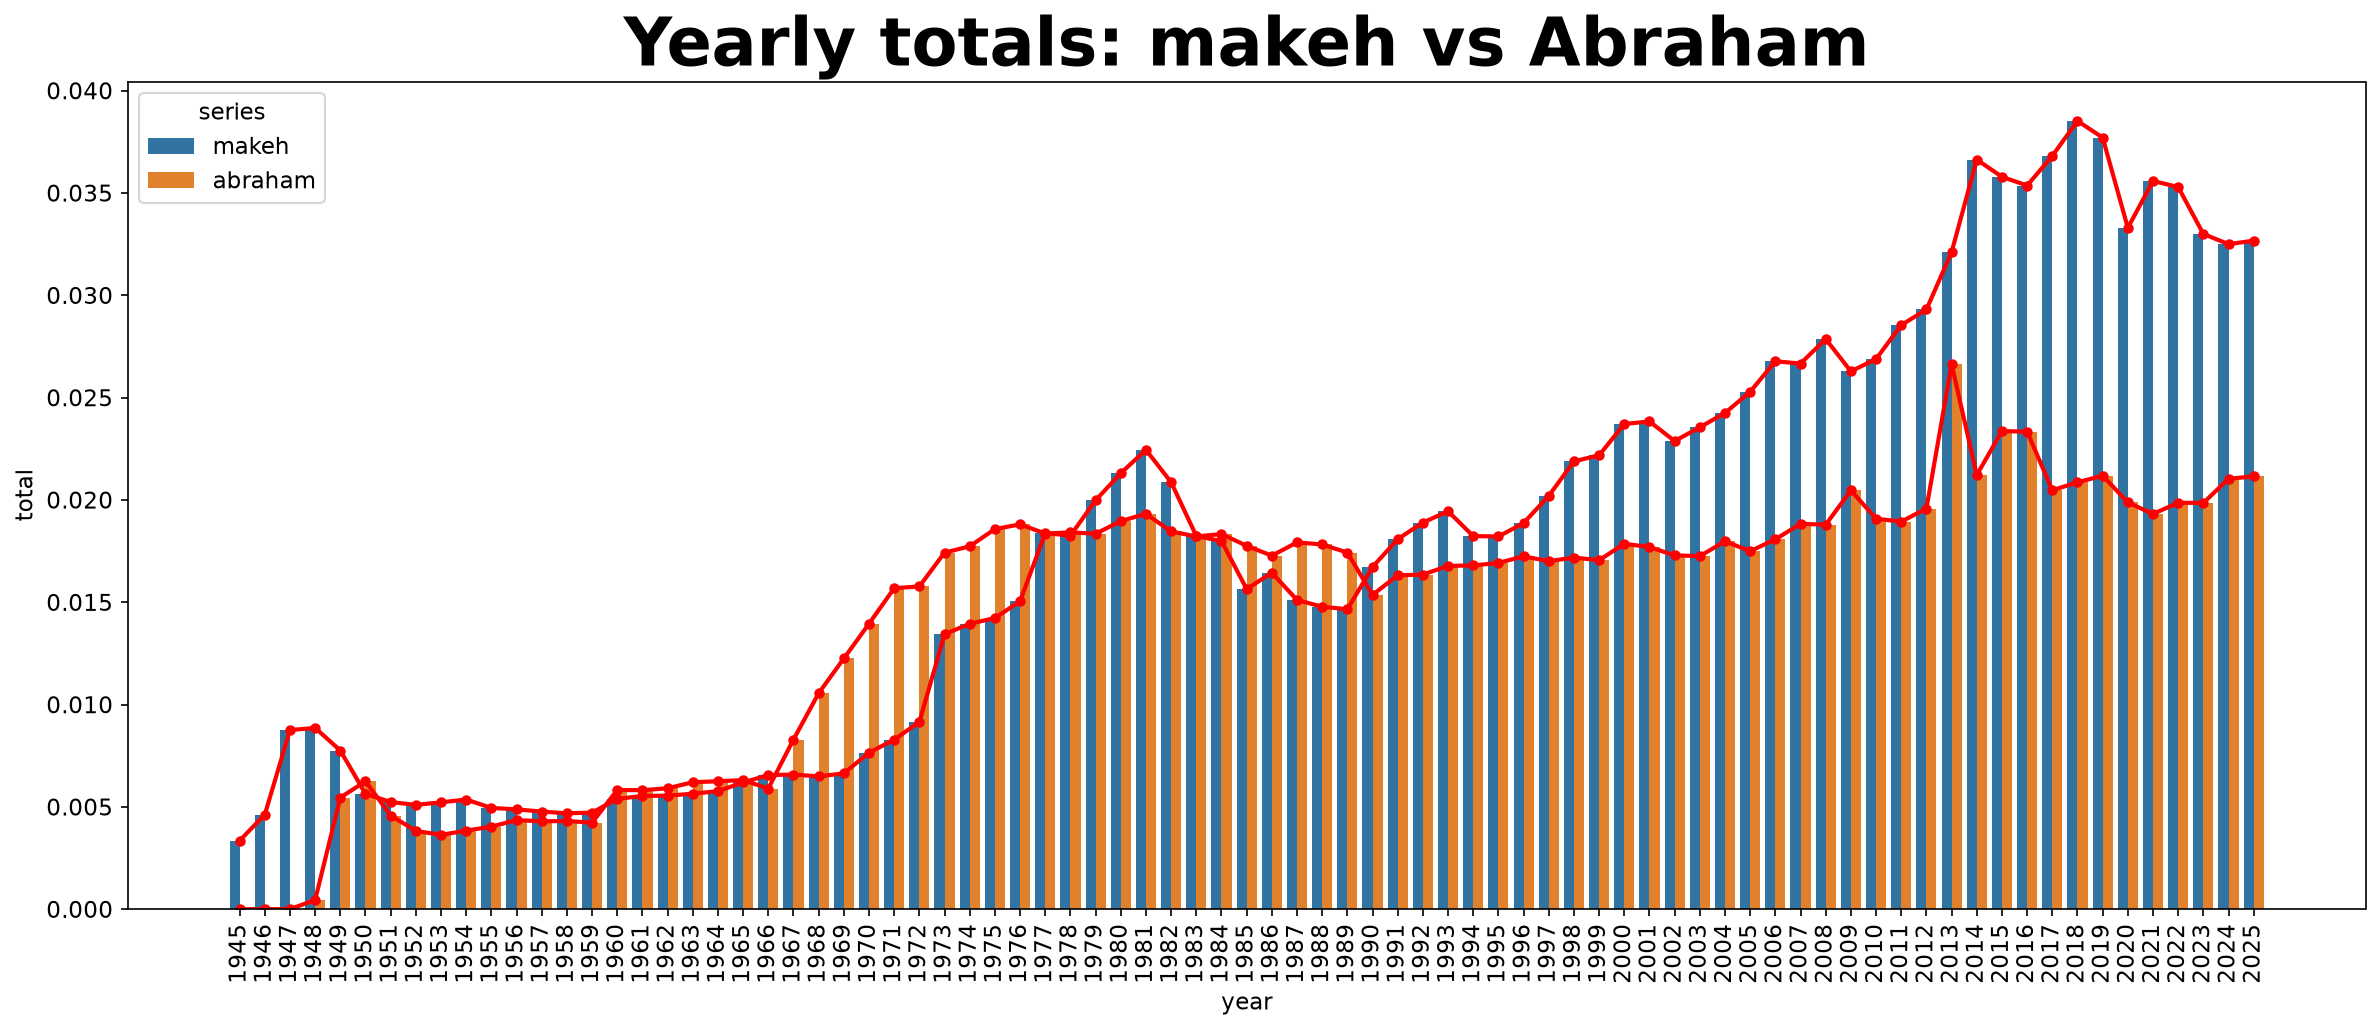

In [107]:
years = df.loc[1945:2025].index          # or df.loc[mask, "year"], whichever you used

plot_df = (
    pd.DataFrame({
        "year": years,
        "makeh":   df.loc[1945:2025, useful_columns].sum(axis=1).to_numpy(),
        "abraham": df.loc[1945:2025, useful_columns1].sum(axis=1).to_numpy(),
    })
    .melt(id_vars="year", var_name="series", value_name="total")
)

fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=plot_df, x="year", y="total", hue="series", ax=ax,orient='v')
for series, color in [("makeh", "#5518D9"), ("abraham", "#B9F33D")]:
    s = plot_df[plot_df["series"] == series]
    # x positions in barplot are 0,1,2,... for each year
    ax.plot(range(len(s)), s["total"].values, 
            color="red", marker="o", linewidth=2, markersize=4,
            label=f"{series} trend")

ax.set_title("Yearly totals: makeh vs Abraham",weight="bold",size=32)
ax.tick_params(axis="x", rotation=90)    # 81 years → rotate labels
plt.tight_layout()
plt.show()

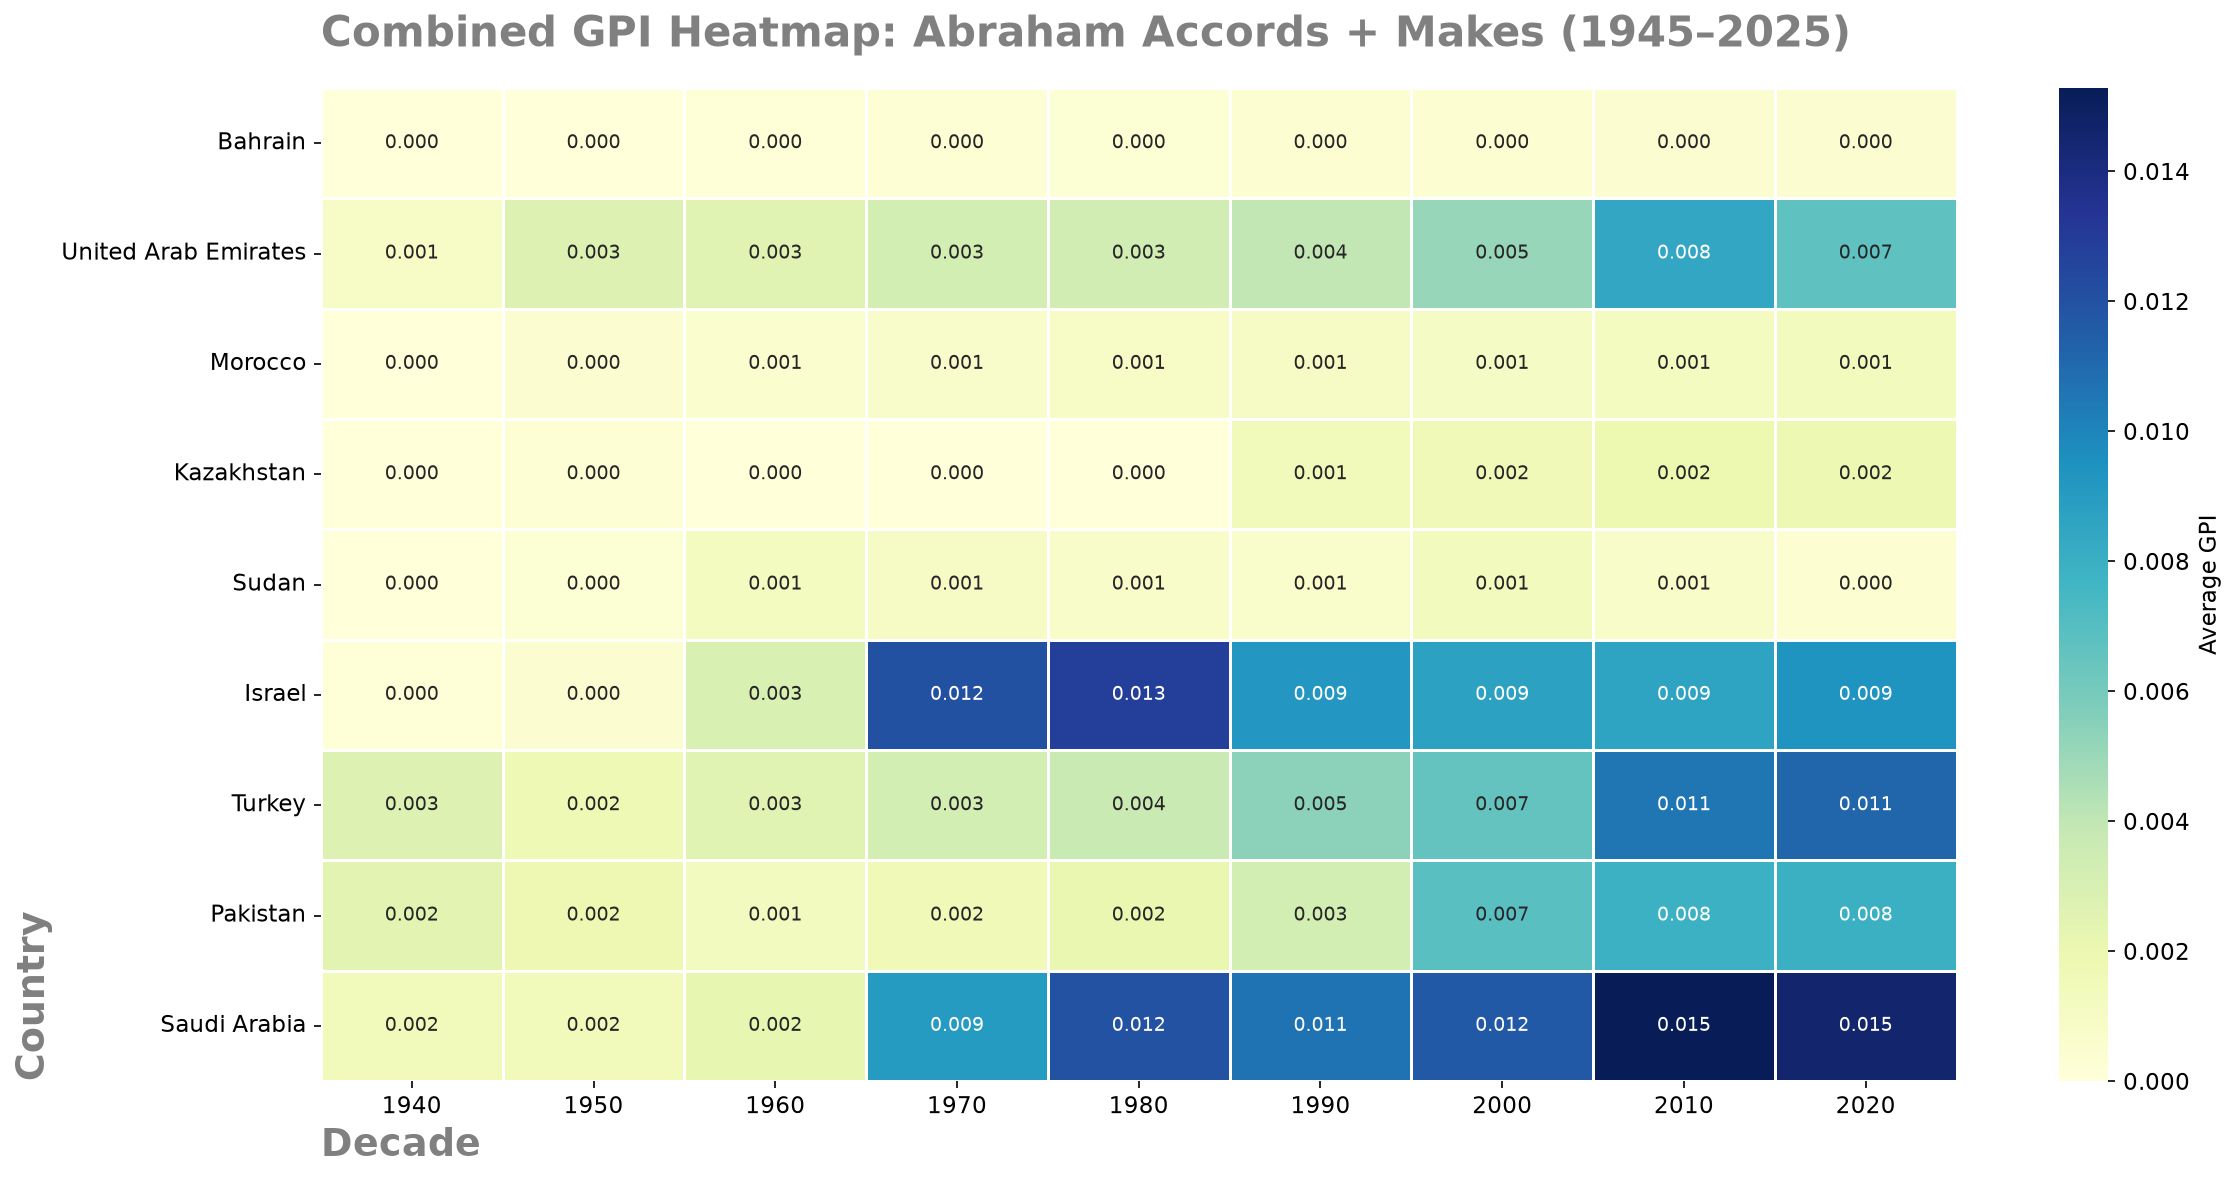

In [110]:
def clean_df(df):
    # حذف ستون‌های sum و total اگر وجود داشته باشند
    cols_to_drop = [c for c in df.columns 
                    if any(k in str(c).lower() for k in ('sum', 'total'))]
    df = df.drop(columns=cols_to_drop, errors='ignore')
    # فقط نگه‌داشتن ستون‌های عددی
    return df.select_dtypes(include="number")

abim_clean = clean_df(abim)
mbim_clean = clean_df(mbim)

# ════════════════════════════════════════════════════════════════════
#  ۲) ترکیب هر دو دیتافریم و حذف ستون‌های تکراری (در صورت وجود)
# ════════════════════════════════════════════════════════════════════
# چسبوندن ستون‌های mbim به abim
combined_df = pd.concat([abim_clean, mbim_clean], axis=1)

# جلوگیری از خطای ستون‌های تکراری (اگر کشوری در هر دو باشد)
combined_df = combined_df.loc[:, ~combined_df.columns.duplicated()]

# اطمینان از اینکه ایندکس از نوع عدد صحیح است
combined_df.index = combined_df.index.astype(int)

# ════════════════════════════════════════════════════════════════════
#  ۳) گروه‌بندی بر اساس دهه (برای خوانایی بهتر)
# ════════════════════════════════════════════════════════════════════
decade_avg = combined_df.groupby((combined_df.index // 10) * 10).mean()

# ════════════════════════════════════════════════════════════════════
#  ۴) رسم هیت‌مپ
# ════════════════════════════════════════════════════════════════════
# سایز رو بر اساس تعداد کشورها کمی تنظیم می‌کنیم تا اعداد جا بشن
n_countries = len(decade_avg.columns)
fig_height = max(8, n_countries * 0.4) 

fig, ax = plt.subplots(figsize=(16, fig_height))

sns.heatmap(
    decade_avg.T,           # ترانسپوز تا کشورها در محور Y و دهه‌ها در محور X باشند
    cmap='YlGnBu',          # طیف رنگی زرد-سبز-آبی (بسیار خوانا)
    annot=True,             # نمایش اعداد
    fmt='.3f',              # ۳ رقم اعشار برای تمیزی
    linewidths=0.5,         # خطوط بین خانه‌ها
    ax=ax,
    cbar_kws={'label': 'Average GPI'},
    annot_kws={"size": 9}   # سایز فونت اعداد
)

# ════════════════════════════════════════════════════════════════════
#  ۵) تنظیمات ظاهری
# ════════════════════════════════════════════════════════════════════
ax.set_title("Combined GPI Heatmap: Abraham Accords + Makes (1945–2025)",
             fontsize=20, fontweight='bold', loc='left', color='gray', pad=20)
ax.set_xlabel("Decade", fontsize=18, fontweight='bold', color='gray',loc='left')
ax.set_ylabel("Country", fontsize=18, fontweight='bold', color='gray',loc='bottom')

plt.tight_layout()
plt.savefig("combined_heatmap.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

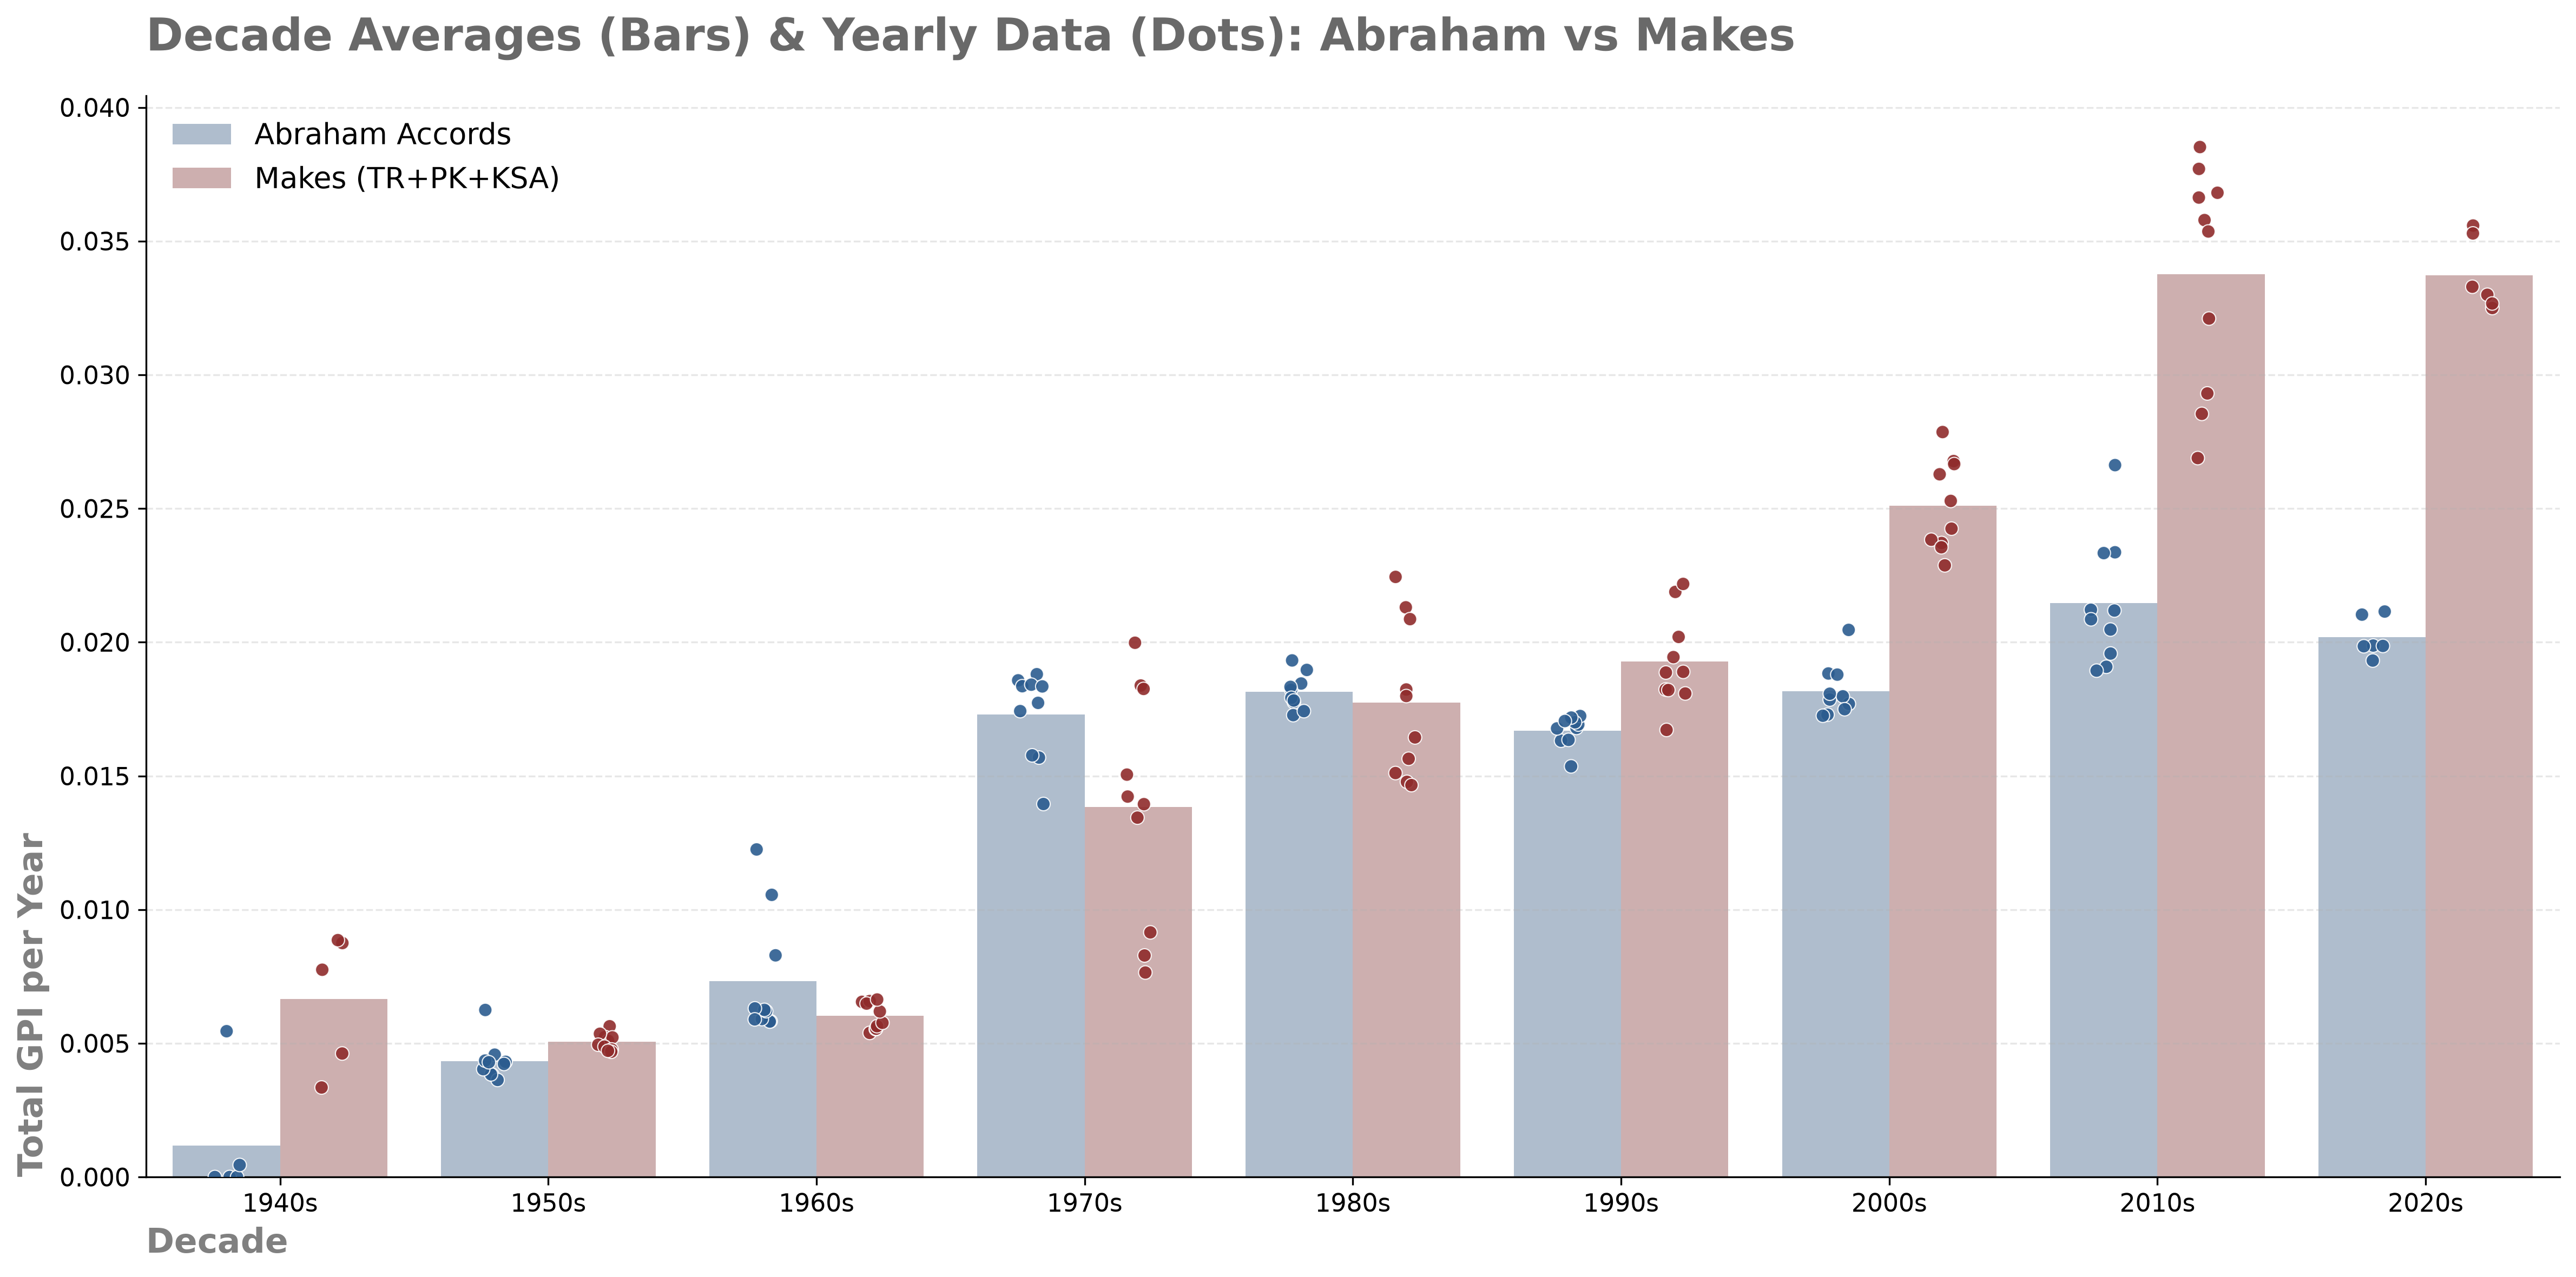

In [116]:
def clean_and_sum(df):
    cols_to_drop = [c for c in df.columns if any(k in str(c).lower() for k in ('sum', 'total'))]
    df = df.drop(columns=cols_to_drop, errors='ignore').select_dtypes(include="number")
    return df.sum(axis=1)

df_abraham = pd.DataFrame({'Year': abim.index, 'Value': clean_and_sum(abim), 'Group': 'Abraham Accords'})
df_makeh   = pd.DataFrame({'Year': mbim.index, 'Value': clean_and_sum(mbim), 'Group': 'Makes (TR+PK+KSA)'})
plot_df = pd.concat([df_abraham, df_makeh], ignore_index=True)

# ساخت ستون دهه
plot_df['Decade'] = (plot_df['Year'] // 10) * 10
plot_df['Decade_Label'] = plot_df['Decade'].astype(str) + 's'

# ════════════════════════════════════════════════════════════════════
#  ۲) رسم نمودار (میله برای میانگین + نقطه برای سال‌ها)
# ════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(16, 8), dpi=300)
palette = {'Abraham Accords': '#2b5c8f', 'Makes (TR+PK+KSA)': '#8f2b2b'}

# ۱. میله‌ها (میانگین دهه)
sns.barplot(
    data=plot_df, 
    x='Decade_Label', y='Value', hue='Group', 
    palette=palette, 
    alpha=0.4,            # شفافیت میله‌ها
    errorbar=None,        # خطای استاندارد رو خاموش می‌کنیم چون نقاط رو خودمون می‌ذاریم
    ax=ax
)

# ۲. نقاط (تک تک سال‌ها)
sns.stripplot(
    data=plot_df, 
    x='Decade_Label', y='Value', hue='Group',
    palette=palette,
    dodge=True,           # نقاط هر گروه سمت خودش
    size=6, 
    alpha=0.9,
    jitter=0.1,           # پخش شدن نقاط
    edgecolor='white',
    linewidth=0.5,
    ax=ax,
    legend=False
)

# ════════════════════════════════════════════════════════════════════
#  ۳) زیباسازی
# ════════════════════════════════════════════════════════════════════
ax.set_title("Decade Averages (Bars) & Yearly Data (Dots): Abraham vs Makes", 
             fontsize=20, fontweight='bold', color='dimgray', loc='left',pad=20)
ax.set_xlabel("Decade", fontsize=15, fontweight='bold', color='gray',loc='left')
ax.set_ylabel("Total GPI per Year", fontsize=15, fontweight='bold', color='gray',loc='bottom')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', alpha=0.3, linestyle='--')

# اصلاح لجند
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:2], labels[:2], loc='upper left', fontsize=13, frameon=False)

plt.tight_layout()
plt.savefig("decade_bar_dots.png", dpi=300, bbox_inches='tight', facecolor='white')
plt.show()